# Hauling Pipeline




## 1. Setup environment

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip -q install ultralytics lap

In [ ]:
from pathlib import Path
import os, sys
DRIVE_DIR      = Path('/content/drive/MyDrive/Hauling Ruby')
MODEL_DIR      = DRIVE_DIR / 'model'
VIDEO          = DRIVE_DIR / 'video/km18_sample.mp4'
VEHICLE_MODEL  = MODEL_DIR / 'Hauling_Vehicle_yolov8m_SingleCls_V11.pt'
PLATE_MODEL    = MODEL_DIR / 'detection_hauling_angka_huruf_V1.pt'
USE_OCR        = True        # baca teks nomor lambung
PLATE_REGION   = '0.3,0.85,0.25,1'  # bagian bbox truk nomor laambung
CONFIG         = DRIVE_DIR / 'config/_track_km18_01_V2.conf'    # config
AUTO_AREA      = False
AUTO_SECONDS   = 120
AUTO_CONFIG    = DRIVE_DIR / 'config/km18_auto.json'
if AUTO_AREA and AUTO_CONFIG.exists():
    CONFIG = AUTO_CONFIG
CONFIG_SECTION = 'CONFIG'
OUTPUT_DIR     = Path('/content/outputs/run_01')
DEMO_SECONDS   = 20


import torch
DEVICE = '0' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == '0' else '')

WORK = Path('/content/hauling'); (WORK / 'hauling_offline').mkdir(parents=True, exist_ok=True); (WORK / 'tests').mkdir(exist_ok=True)
os.chdir(WORK); sys.path.insert(0, str(WORK))
for name, p in [('VIDEO', VIDEO), ('VEHICLE_MODEL', VEHICLE_MODEL), ('PLATE_MODEL', PLATE_MODEL), ('CONFIG', CONFIG)]:
    print(f"{'OK     ' if p and Path(p).exists() else 'MISSING'} {name:14s} {p}")

Device: 0 Tesla T4
OK      VIDEO          /content/drive/MyDrive/Hauling Ruby/video/km18_sample.mp4
OK      VEHICLE_MODEL  /content/drive/MyDrive/Hauling Ruby/model/Hauling_Vehicle_yolov8m_SingleCls_V11.pt
OK      PLATE_MODEL    /content/drive/MyDrive/Hauling Ruby/model/detection_hauling_angka_huruf_V1.pt
OK      CONFIG         /content/drive/MyDrive/Hauling Ruby/config/_track_km18_01_V2.conf


In [ ]:
import glob, zipfile, ast, sys, shutil
from pathlib import Path

cands = sorted(glob.glob('/content/drive/MyDrive/**/hauling_offline.zip', recursive=True),
               key=lambda p: Path(p).stat().st_mtime, reverse=True)
if cands:
    zip_path = cands[0]
else:
    from google.colab import files
    print('Zip tidak ada di Drive -> pilih hauling_offline.zip dari laptop')
    up = files.upload()
    zip_path = '/content/' + next(iter(up))

    shutil.copy(zip_path, '/content/drive/MyDrive/Hauling Ruby/hauling_offline.zip')
print('Memakai zip:', zip_path)
zipfile.ZipFile(zip_path).extractall('/content/hauling')

bad = []
for f in sorted(Path('/content/hauling/hauling_offline').glob('*.py')):
    try:
        ast.parse(f.read_text(encoding='utf-8'))
    except SyntaxError as e:
        bad.append(f'{f.name} (baris {e.lineno})')
print('Modul terpasang:', sorted(p.name for p in Path('/content/hauling/hauling_offline').glob('*.py')))
print('File rusak:', bad or 'tidak ada')

sys.path.insert(0, '/content/hauling')
for name in list(sys.modules):
    if name.startswith('hauling_offline'):
        del sys.modules[name]
import hauling_offline.tracks as T, hauling_offline.vehicle_type as VT, hauling_offline.report as R
print('lambung hanya di area final :', 'plate_zone' in T.TrackManager.__init__.__code__.co_varnames)
print('Truck vs Light Vehicle      :', VT.VEHICLE_TYPES)
print('laporan per ID              :', R.TRACK_HEADER[:4], '...')

Memakai zip: /content/drive/MyDrive/Hauling Ruby/hauling_offline.zip
Modul terpasang: ['__init__.py', 'auto_area.py', 'cli.py', 'config.py', 'csv_writer.py', 'detector.py', 'geometry.py', 'ocr.py', 'pipeline.py', 'plate.py', 'renderer.py', 'report.py', 'speed.py', 'tracks.py', 'vehicle_type.py']
File rusak: tidak ada
lambung hanya di area final : True
Truck vs Light Vehicle      : ('Truck', 'Light Vehicle')
laporan per ID              : ['track_id', 'vehicle_type', 'vehicle_type_confidence', 'vehicle_type_source'] ...


In [ ]:

!find "$DRIVE_DIR" -maxdepth 3 \( -name "*.mp4" -o -name "*.avi" -o -name "*.pt" -o -name "*.onnx" -o -name "*.json" -o -name "*.yaml" -o -name "*.ini" -o -name "*.env" -o -name "*.cfg" \) | head -50

/content/drive/MyDrive/Hauling Ruby/model/Hauling_Vehicle_yolov8m_SingleCls_V11.pt
/content/drive/MyDrive/Hauling Ruby/model/Hauling_Vehicle_yolov8m_SingleCls_V10_1.pt
/content/drive/MyDrive/Hauling Ruby/model/Hauling_Vehicle_yolov8m_SingleCls_V10_3.pt
/content/drive/MyDrive/Hauling Ruby/model/Hauling_Vehicle_yolov8m_SingleCls_V10_4.pt
/content/drive/MyDrive/Hauling Ruby/model/detection_hauling_angka_huruf_V1.pt
/content/drive/MyDrive/Hauling Ruby/model/classification_hauling_angka_yolo8m_imgz96_v9.pt
/content/drive/MyDrive/Hauling Ruby/model/Classification_truck_mitra_yolov8m_Imgz224_V3.pt
/content/drive/MyDrive/Hauling Ruby/model/character_angka_detection_hauling_yolov8m_V2.pt
/content/drive/MyDrive/Hauling Ruby/model/character_huruf_detection_hauling_yolov8m_V2.pt
/content/drive/MyDrive/Hauling Ruby/model/classification_hauling_huruf_yolo8m_imgz96_v9.pt
/content/drive/MyDrive/Hauling Ruby/model/No_Lambung_TruckHD_Detection_yolov8m_V3.pt
/content/drive/MyDrive/Hauling Ruby/config/km1

### 1b. Analisis 11 model di folder `model/`



In [ ]:
import pandas as pd
from ultralytics import YOLO
rows = []
for f in sorted(MODEL_DIR.glob('*.pt')):
    m = YOLO(str(f)); ck = getattr(m, 'ckpt', {}) or {}; ta = ck.get('train_args', {}) or {}
    met = {k.split('/')[-1]: round(v, 3) for k, v in (ck.get('train_metrics') or {}).items() if k.startswith('metrics/')}
    rows.append(dict(file=f.name, MB=round(f.stat().st_size / 1e6, 1), task=m.task, imgsz=ta.get('imgsz'),
                     single_cls=ta.get('single_cls'), names=m.names, epoch=ck.get('epoch'), date=str(ck.get('date'))[:10], **met))
pd.set_option('display.max_colwidth', 120); pd.DataFrame(rows)

,file,MB,task,imgsz,single_cls,names,epoch,date,accuracy_top1,accuracy_top5,precision(B),recall(B),mAP50(B),mAP50-95(B)
0,Classification_truck_mitra_yolov8m_Imgz224_V3.pt,31.7,classify,224,False,"{0: 'truck batu bara', 1: 'truck non batu bara'}",-1,2025-11-21,0.988,1.000,NaN,NaN,NaN,NaN
1,Hauling_Vehicle_yolov8m_SingleCls_V10_1.pt,52.0,detect,640,True,"{0: 'Truck', 1: 'Light Vehicle', 2: 'Motorcycle', 3: 'Bus', 4: 'Person'}",-1,2024-10-13,NaN,NaN,0.987,0.986,0.994,0.929
2,Hauling_Vehicle_yolov8m_SingleCls_V10_3.pt,52.0,detect,640,True,"{0: 'Truck', 1: 'Light Vehicle', 2: 'Motorcycle', 3: 'Bus', 4: 'Grader'}",-1,2025-06-24,NaN,NaN,0.984,0.986,0.994,0.933
3,Hauling_Vehicle_yolov8m_SingleCls_V10_4.pt,103.8,detect,640,True,"{0: 'Truck', 1: 'Light Vehicle', 2: 'Motorcycle', 3: 'Bus', 4: 'Grader'}",9,2025-10-10,NaN,NaN,0.979,0.982,0.993,0.901
4,Hauling_Vehicle_yolov8m_SingleCls_V11.pt,52.0,detect,640,True,"{0: 'Truck', 1: 'Light Vehicle', 2: 'Motorcycle', 3: 'Bus', 4: 'Grader'}",-1,2025-11-11,NaN,NaN,0.984,0.977,0.993,0.918
5,No_Lambung_TruckHD_Detection_yolov8m_V3.pt,52.0,detect,640,False,{0: 'Character'},-1,2025-05-31,NaN,NaN,0.981,0.990,0.994,0.883
6,character_angka_detection_hauling_yolov8m_V2.pt,52.0,detect,224,False,{0: 'class_0'},-1,2025-11-05,NaN,NaN,0.995,0.997,0.994,0.776
7,character_huruf_detection_hauling_yolov8m_V2.pt,52.0,detect,224,False,{0: 'class_0'},-1,2025-11-05,NaN,NaN,0.995,0.996,0.994,0.799
8,classification_hauling_angka_yolo8m_imgz96_v9.pt,31.7,classify,96,False,"{0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9'}",-1,2025-12-31,0.974,0.997,NaN,NaN,NaN,NaN
9,classification_hauling_huruf_yolo8m_imgz96_v9.pt,31.7,classify,96,False,"{0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E', 5: 'G', 6: 'H', 7: 'I', 8: 'J', 9: 'K', 10: 'L', 11: 'M', 12: 'N', 13: 'O',...",-1,2025-12-31,0.977,0.997,NaN,NaN,NaN,NaN


In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt

def show(img_bgr, title='', w=14):
    h, wd = img_bgr.shape[:2]
    plt.figure(figsize=(w, w * h / wd)); plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title); plt.axis('off'); plt.show()

def read_frame(path, frame_index=0):
    cap = cv2.VideoCapture(str(path)); cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    ok, f = cap.read(); cap.release()
    assert ok, f'Gagal membaca frame {frame_index} dari {path}'
    return f

cap = cv2.VideoCapture(str(VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS); W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
N = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); cap.release()
print(f'Video: {W}x{H} @ {FPS:.2f} fps, {N} frame (~{N / FPS:.1f} s)')

Video: 1920x1080 @ 30.00 fps, 1743 frame (~58.1 s)


In [ ]:
%%writefile hauling_offline/__init__.py
"""Pipeline inference hauling offline (video file -> events.csv + annotated.mp4 + run_summary.json)."""

__version__ = "0.1.0"

Overwriting hauling_offline/__init__.py


---
## 2. Setup Area



In [ ]:
import glob, zipfile, ast, importlib, sys
from pathlib import Path

cands = sorted(glob.glob('/content/drive/MyDrive/**/hauling_offline_src*.zip', recursive=True),
               key=lambda p: Path(p).stat().st_mtime, reverse=True)
assert cands, 'Zip belum ada di Drive -> upload hauling_offline_src.zip ke folder Hauling Ruby'
print('Memakai zip:', cands[0])
zipfile.ZipFile(cands[0]).extractall('/content/hauling')

bad = []
for f in sorted(Path('/content/hauling/hauling_offline').glob('*.py')):
    try:
        ast.parse(f.read_text(encoding='utf-8'))
    except SyntaxError as e:
        bad.append(f'{f.name} (baris {e.lineno})')
print('File rusak:', bad or 'tidak ada')

sys.path.insert(0, '/content/hauling')
for name in list(sys.modules):
    if name.startswith('hauling_offline'):
        del sys.modules[name]
import hauling_offline.tracks as T, hauling_offline.vehicle_type as VT, hauling_offline.report as R
print('lambung hanya di area final :', 'plate_zone' in T.TrackManager.__init__.__code__.co_varnames)
print('Truck vs Light Vehicle      :', VT.VEHICLE_TYPES)
print('laporan per ID              :', R.TRACK_HEADER[:4], '...')

Memakai zip: /content/drive/MyDrive/Hauling Ruby/hauling_offline_src.zip
File rusak: tidak ada
crossing garis tipis aktif : True
baca conf_model/iou_model  : True
filter nomor lambung aktif : True
grace + voting format aktif: True


In [ ]:
%%writefile hauling_offline/geometry.py
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np

from .config import KM18Config, Polygon

AREA_ORDER = ("main", "speed_start", "speed_final", "final")


def scale_polygon(poly: Polygon, base_res: Tuple[int, int], frame_res: Tuple[int, int]) -> np.ndarray:
    """Skala proporsional dari resolution_area (w,h) ke resolusi frame (w,h). Output int32 (N,2)."""
    bw, bh = base_res
    fw, fh = frame_res
    arr = np.asarray(poly, dtype=np.float64)
    if (bw, bh) != (fw, fh):
        arr = arr * np.array([fw / bw, fh / bh], dtype=np.float64)
    return np.round(arr).astype(np.int32)


def bbox_center(xyxy: Sequence[float]) -> Tuple[float, float]:
    x1, y1, x2, y2 = xyxy
    return (x1 + x2) / 2.0, (y1 + y2) / 2.0


def point_in_polygon(point: Tuple[float, float], poly: np.ndarray) -> bool:
    """True bila titik di dalam ATAU tepat di garis polygon (ray casting, tanpa dependensi cv2)."""
    x, y = float(point[0]), float(point[1])
    pts = np.asarray(poly, dtype=np.float64)
    n = len(pts)
    inside = False
    for i in range(n):
        x1, y1 = pts[i]
        x2, y2 = pts[(i + 1) % n]
        # titik tepat di sisi polygon -> dianggap menyentuh
        cross = (x - x1) * (y2 - y1) - (y - y1) * (x2 - x1)
        if abs(cross) < 1e-9 and min(x1, x2) - 1e-9 <= x <= max(x1, x2) + 1e-9 and min(y1, y2) - 1e-9 <= y <= max(y1, y2) + 1e-9:
            return True
        if (y1 > y) != (y2 > y):
            x_int = x1 + (y - y1) * (x2 - x1) / (y2 - y1)
            if x < x_int:
                inside = not inside
    return inside


def _seg_intersect(p1, p2, q1, q2) -> bool:
    """True bila segmen p1-p2 dan q1-q2 berpotongan (termasuk menyentuh)."""
    def orient(a, b, c):
        v = (b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0])
        return 0 if abs(v) < 1e-9 else (1 if v > 0 else -1)

    def on_seg(a, b, c):
        return min(a[0], b[0]) - 1e-9 <= c[0] <= max(a[0], b[0]) + 1e-9 and \
            min(a[1], b[1]) - 1e-9 <= c[1] <= max(a[1], b[1]) + 1e-9

    o1, o2, o3, o4 = orient(p1, p2, q1), orient(p1, p2, q2), orient(q1, q2, p1), orient(q1, q2, p2)
    if o1 != o2 and o3 != o4:
        return True
    return (o1 == 0 and on_seg(p1, p2, q1)) or (o2 == 0 and on_seg(p1, p2, q2)) or \
        (o3 == 0 and on_seg(q1, q2, p1)) or (o4 == 0 and on_seg(q1, q2, p2))


def segment_touches_polygon(p0: Tuple[float, float], p1: Tuple[float, float], poly: np.ndarray) -> bool:
    """True bila centroid sekarang (p1) di dalam polygon ATAU lintasan p0->p1 memotong polygon.

    Penting untuk area tipis (mis. garis start/finish KM-18 setebal ~10 px): pada fps rendah centroid bisa
    'melompati' garis di antara dua frame; lintasan antar-frame tetap terdeteksi memotong garis.
    """
    if point_in_polygon(p1, poly):
        return True
    pts = np.asarray(poly, dtype=np.float64)
    n = len(pts)
    return any(_seg_intersect(p0, p1, pts[i], pts[(i + 1) % n]) for i in range(n))


@dataclass
class AreaSet:
    """Semua polygon area yang sudah diskalakan ke resolusi frame video."""
    polygons: Dict[str, List[np.ndarray]]
    frame_res: Tuple[int, int]

    @classmethod
    def from_config(cls, cfg: KM18Config, frame_res: Tuple[int, int]) -> "AreaSet":
        polys = {
            name: [scale_polygon(p, cfg.resolution, frame_res) for p in cfg.areas[name]]
            for name in AREA_ORDER
        }
        return cls(polygons=polys, frame_res=frame_res)

    def contains(self, area: str, point: Tuple[float, float]) -> bool:
        return any(point_in_polygon(point, p) for p in self.polygons[area])

    def touches(self, area: str, point: Tuple[float, float], prev: Optional[Tuple[float, float]] = None) -> bool:
        """contains(), ditambah: lintasan prev->point memotong area (crossing antar-frame)."""
        if prev is None:
            return self.contains(area, point)
        return any(segment_touches_polygon(prev, point, p) for p in self.polygons[area])

    def areas_of(self, point: Tuple[float, float]) -> Dict[str, bool]:
        return {name: self.contains(name, point) for name in AREA_ORDER}

Overwriting hauling_offline/geometry.py


### 2.1 Auto-generate area KM-18 (otomatis dari lintasan truk)



In [ ]:
%%writefile hauling_offline/detector.py
"""TASK 2 - Deteksi Kendaraan: adapter detector + multi-object tracker (Ultralytics YOLO + ByteTrack)."""
from __future__ import annotations

import os
import tempfile
from dataclasses import dataclass
from pathlib import Path
from typing import List, Optional, Sequence

import numpy as np


os.environ.setdefault("YOLO_OFFLINE", "1")

COCO_VEHICLE_NAMES = {"car", "motorcycle", "bus", "truck"}


@dataclass(frozen=True)
class Detection:
    track_id: Optional[int]
    bbox_xyxy: tuple
    confidence: float
    class_id: int
    class_name: str = "Vehicle"


def model_train_args(yolo_model) -> dict:

    ckpt = getattr(yolo_model, "ckpt", None) or {}
    args = ckpt.get("train_args") if isinstance(ckpt, dict) else None
    return dict(args or {})


def auto_vehicle_classes(names: dict, train_args: Optional[dict] = None) -> Optional[List[int]]:

    """
    if (train_args or {}).get("single_cls"):
        return None
    lower = {int(i): str(n).strip().lower() for i, n in names.items()}
    exact = [i for i, n in lower.items() if n == "vehicle"]
    if exact:
        return exact
    coco = [i for i, n in lower.items() if n in COCO_VEHICLE_NAMES]
    if len(coco) == len(COCO_VEHICLE_NAMES) and len(lower) >= 80:
        return coco
    return None


def write_tracker_yaml(track_buffer_frames: int, out_dir: Path, tracker: str = "bytetrack") -> Path:
    """Buat file tracker custom dengan track_buffer sesuai fps (toleransi occlusion pendek)."""
    import ultralytics
    base = Path(ultralytics.__file__).parent / "cfg" / "trackers" / f"{tracker}.yaml"
    lines = []
    for line in base.read_text(encoding="utf-8").splitlines():
        if line.strip().startswith("track_buffer:"):
            line = f"track_buffer: {int(track_buffer_frames)}"
        lines.append(line)
    out_dir.mkdir(parents=True, exist_ok=True)
    out = out_dir / f"{tracker}_hauling.yaml"
    out.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return out


class VehicleTracker:
    """Jalankan model vehicle + tracking per frame. Hasilnya list Detection ber-track_id."""

    def __init__(
        self,
        model_path: str,
        conf: float = 0.25,
        iou: float = 0.5,
        imgsz: Optional[int] = None,       # None -> imgsz saat training model
        max_det: int = 100,
        device: Optional[str] = None,
        classes: Optional[Sequence[int]] = None,
        track_buffer_frames: int = 60,
        tracker: str = "bytetrack",
    ):
        from ultralytics import YOLO
        self.model = YOLO(model_path)
        self.names = self.model.names if isinstance(self.model.names, dict) else dict(enumerate(self.model.names))
        self.train_args = model_train_args(self.model)
        if imgsz is None:
            imgsz = self.train_args.get("imgsz") or 640
        self.conf, self.iou, self.imgsz, self.max_det, self.device = conf, iou, int(imgsz), int(max_det), device
        self.classes = list(classes) if classes is not None else auto_vehicle_classes(self.names, self.train_args)
        tmp = Path(tempfile.mkdtemp(prefix="hauling_trk_"))
        self.tracker_cfg = str(write_tracker_yaml(track_buffer_frames, tmp, tracker))

    def track(self, frame: np.ndarray) -> List[Detection]:
        kwargs = dict(
            persist=True, tracker=self.tracker_cfg, conf=self.conf, iou=self.iou,
            imgsz=self.imgsz, max_det=self.max_det, classes=self.classes, verbose=False,
        )
        if self.device:
            kwargs["device"] = self.device
        res = self.model.track(frame, **kwargs)[0]
        boxes = res.boxes
        if boxes is None or len(boxes) == 0:
            return []
        xyxy = boxes.xyxy.cpu().numpy()
        conf = boxes.conf.cpu().numpy()
        cls = boxes.cls.cpu().numpy().astype(int)
        ids = boxes.id.cpu().numpy().astype(int) if boxes.id is not None else [None] * len(xyxy)
        return [
            Detection(
                track_id=(int(t) if t is not None else None),
                bbox_xyxy=tuple(float(v) for v in b),
                confidence=round(float(c), 4),
                class_id=int(k),
            )
            for b, c, k, t in zip(xyxy, conf, cls, ids)
        ]

Overwriting hauling_offline/detector.py


In [ ]:
%%writefile hauling_offline/auto_area.py

from __future__ import annotations

import argparse
import json
import logging
import sys
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import cv2
import numpy as np

from .geometry import point_in_polygon

log = logging.getLogger("hauling.auto_area")

# (frame_index, cx, cy, w, h)
TrackPoint = Tuple[int, float, float, float, float]


@dataclass
class AutoAreaResult:
    config: dict
    direction_vector: Tuple[float, float]
    n_tracks_used: int
    coverage: Dict[str, int] = field(default_factory=dict)
    warnings: List[str] = field(default_factory=list)



def build_areas(
    tracks: Dict[int, Sequence[TrackPoint]],
    frame_size: Tuple[int, int],
    start_frac: float = 0.12,
    finish_frac: float = 0.62,
    final_frac: float = 0.78,
    min_points: int = 8,
    min_travel_ratio: float = 0.15,
    distance_meter: float = 47.0,
    speed_limit: float = 60.0,
) -> AutoAreaResult:
    w, h = frame_size
    warnings: List[str] = []

    moving = {}
    for tid, pts in tracks.items():
        if len(pts) < min_points:
            continue
        arr = np.asarray(pts, dtype=np.float64)
        disp = arr[-1, 1:3] - arr[0, 1:3]
        if np.hypot(*disp) >= min_travel_ratio * min(w, h):
            moving[tid] = arr
    if not moving:
        raise ValueError("Tidak ada kendaraan yang bergerak cukup jauh di potongan video. "
                         "Perpanjang durasi (seconds) atau pilih bagian video yang ada truk lewat.")
    if len(moving) < 3:
        warnings.append(f"Hanya {len(moving)} track bergerak dipakai; area bisa kurang akurat (disarankan >= 3).")


    vecs = np.array([a[-1, 1:3] - a[0, 1:3] for a in moving.values()])
    units = vecs / np.linalg.norm(vecs, axis=1, keepdims=True)
    ref = units[np.argmax(np.linalg.norm(vecs, axis=1))]
    signs = np.sign(units @ ref)
    u = (units * signs[:, None] * np.linalg.norm(vecs, axis=1, keepdims=True)).sum(0)
    u = u / np.linalg.norm(u)
    if (signs < 0).sum() > (signs > 0).sum():
        u = -u
    n_opposite = int((np.sign(units @ u) < 0).sum())
    if n_opposite:
        warnings.append(f"{n_opposite} track bergerak berlawanan arah; diabaikan untuk penentuan arah.")
    direction = "South" if u[1] > 0 else "North"


    ax = 1 if abs(u[1]) >= abs(u[0]) else 0
    sgn = 1.0 if u[ax] > 0 else -1.0
    if ax == 0:
        direction = "East" if u[0] > 0 else "West"
        warnings.append("Arah gerak dominan horizontal; travel_direction diisi East/West.")
    length, width = (w, h)[ax], (w, h)[1 - ax]
    P = np.concatenate(list(moving.values()))
    along = P[:, 1 + ax]
    half_w = P[:, 3 + (1 - ax)] / 2
    lo_e, hi_e = P[:, 2 - ax] - half_w, P[:, 2 - ax] + half_w
    edges_bins = np.linspace(along.min(), along.max(), 9)
    bc, bl, bh = [], [], []
    for b0, b1 in zip(edges_bins[:-1], edges_bins[1:]):
        m = (along >= b0) & (along <= b1)
        if m.sum() >= 3:
            bc.append(along[m].mean()); bl.append(np.percentile(lo_e[m], 5)); bh.append(np.percentile(hi_e[m], 95))
    if len(bc) >= 2:
        fl, fh = np.polyfit(bc, bl, 1), np.polyfit(bc, bh, 1)
    else:
        fl, fh = np.array([0.0, lo_e.min()]), np.array([0.0, hi_e.max()])

    def road_edges(t: float, extra: float = 0.10) -> Tuple[float, float]:
        l, r = np.polyval(fl, t), np.polyval(fh, t)
        mg = extra * (r - l)
        return float(np.clip(l - mg, 0, width - 1)), float(np.clip(r + mg, 0, width - 1))

    def xy(a_: float, c_: float) -> List[int]:
        return [int(round(c_)), int(round(a_))] if ax == 1 else [int(round(a_)), int(round(c_))]

    a0, a1 = 0.0, float(length - 1)
    road = [xy(a0, road_edges(a0)[0]), xy(a0, road_edges(a0)[1]), xy(a1, road_edges(a1)[1]), xy(a1, road_edges(a1)[0])]


    s_all = along * sgn
    s_lo, s_hi = np.percentile(s_all, 3), np.percentile(s_all, 97)
    span = s_hi - s_lo
    if span < 0.2 * length:
        warnings.append("Lintasan pendek (<20% frame); garis start/finish/final berdekatan.")
    steps = np.concatenate([np.abs(np.diff(arr[:, 1 + ax])) / np.maximum(np.diff(arr[:, 0]), 1) for arr in moving.values()])
    thick = max(0.012 * length, 2.5 * float(np.percentile(steps, 95)) if len(steps) else 0.0)

    def band(frac: float) -> List[List[int]]:
        c = sgn * (s_lo + frac * span)
        l, r = road_edges(c, extra=0.15)
        return [xy(c - thick / 2, l), xy(c - thick / 2, r), xy(c + thick / 2, r), xy(c + thick / 2, l)]

    config = {
        "resolution_area": f"{w}x{h}",
        "main_area_coordinates_list": road,
        "speed_area_start_coordinates_list": band(start_frac),
        "speed_area_final_coordinates_list": band(finish_frac),
        "final_area_coordinates_list": band(final_frac),
        "distance_area_speed": distance_meter,
        "speed_limit": speed_limit,
        "travel_direction": direction,
        "auto_generated": True,
        "auto_notes": "Area dibuat otomatis dari lintasan kendaraan. distance_area_speed BELUM dikalibrasi "
                      "terhadap jarak nyata antar pita start-final; konfirmasi ke mentor sebelum hasil speed dipakai.",
    }

    polys = {k: np.asarray(config[k], dtype=np.float64) for k in (
        "main_area_coordinates_list", "speed_area_start_coordinates_list",
        "speed_area_final_coordinates_list", "final_area_coordinates_list")}
    ok = 0
    same_dir = [a for a in moving.values() if (a[-1, 1:3] - a[0, 1:3]) @ u > 0]
    for a in same_dir:
        seq = []
        for _, cx, cy, _, _ in a:
            if not point_in_polygon((cx, cy), polys["main_area_coordinates_list"]):
                continue
            for name, key in (("start", "speed_area_start_coordinates_list"),
                              ("finish", "speed_area_final_coordinates_list"),
                              ("final", "final_area_coordinates_list")):
                if name not in seq and point_in_polygon((cx, cy), polys[key]):
                    seq.append(name)
        ok += int(seq[:3] == ["start", "finish", "final"])
    coverage = {"tracks_same_direction": len(same_dir), "tracks_start_finish_final": ok}
    if same_dir and ok < len(same_dir):
        warnings.append(f"{len(same_dir) - ok}/{len(same_dir)} track searah tidak melewati start->finish->final "
                        "(mungkin muncul/hilang di tengah frame).")

    return AutoAreaResult(config, (float(u[0]), float(u[1])), len(moving), coverage, warnings)


def collect_tracks(
    video: str | Path,
    vehicle_model: str | Path,
    seconds: float = 120.0,
    device: Optional[str] = None,
    conf: float = 0.3,
    stride: int = 1,
) -> Tuple[Dict[int, List[TrackPoint]], Tuple[int, int], float]:
    from .detector import VehicleTracker
    cap = cv2.VideoCapture(str(video))
    if not cap.isOpened():
        raise FileNotFoundError(f"Video tidak bisa dibuka: {video}")
    fps = float(cap.get(cv2.CAP_PROP_FPS) or 25.0)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    tracker = VehicleTracker(str(vehicle_model), conf=conf, device=device, track_buffer_frames=int(2 * fps))
    tracks: Dict[int, List[TrackPoint]] = {}
    max_frames = int(seconds * fps)
    fi = -1
    while fi + 1 < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        fi += 1
        if fi % stride:
            continue
        for d in tracker.track(frame):
            if d.track_id is None:
                continue
            x1, y1, x2, y2 = d.bbox_xyxy
            tracks.setdefault(d.track_id, []).append((fi, (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1))
    cap.release()
    return tracks, (w, h), fps


def generate_config(
    video: str | Path,
    vehicle_model: str | Path,
    out_path: str | Path,
    seconds: float = 120.0,
    distance_meter: float = 47.0,
    speed_limit: float = 60.0,
    device: Optional[str] = None,
    stride: int = 1,
) -> AutoAreaResult:
    tracks, size, fps = collect_tracks(video, vehicle_model, seconds, device, stride=stride)
    log.info("lintasan terkumpul: %d track dari %.0f detik video", len(tracks), seconds)
    res = build_areas(tracks, size, distance_meter=distance_meter, speed_limit=speed_limit)
    out = Path(out_path)
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(json.dumps(res.config, indent=2), encoding="utf-8")
    return res


def draw_preview(frame: np.ndarray, config: dict, tracks: Optional[Dict[int, Sequence[TrackPoint]]] = None,
                 alpha: float = 0.15) -> np.ndarray:
    """Outline area + isi transparan rendah (alpha) + lintasan truk."""
    style = [("main_area_coordinates_list", (255, 160, 0), "road"),
             ("speed_area_start_coordinates_list", (0, 200, 0), "start"),
             ("speed_area_final_coordinates_list", (0, 210, 255), "finish"),
             ("final_area_coordinates_list", (255, 0, 200), "final")]
    ov = frame.copy()
    for k, c, _ in style:
        cv2.fillPoly(ov, [np.asarray(config[k], np.int32).reshape(-1, 1, 2)], c)
    img = cv2.addWeighted(ov, alpha, frame, 1 - alpha, 0)
    if tracks:
        for pts in tracks.values():
            arr = np.asarray([[p[1], p[2]] for p in pts], dtype=np.int32)
            if len(arr) > 1:
                cv2.polylines(img, [arr.reshape(-1, 1, 2)], False, (200, 200, 200), 1, cv2.LINE_AA)
    for k, c, name in style:
        p = np.asarray(config[k], np.int32)
        cv2.polylines(img, [p.reshape(-1, 1, 2)], True, c, 2, cv2.LINE_AA)
        if name != "road":
            x, y = p.min(0)
            cv2.putText(img, name, (int(x), int(y) - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.8, c, 2, cv2.LINE_AA)
    return img


def main(argv=None) -> int:
    p = argparse.ArgumentParser(description="Generate config area KM-18 otomatis dari lintasan kendaraan")
    p.add_argument("--video", required=True, type=Path)
    p.add_argument("--vehicle-model", required=True, type=Path)
    p.add_argument("--out", required=True, type=Path, help="path file config output (.json)")
    p.add_argument("--seconds", type=float, default=120.0, help="durasi video yang dianalisis")
    p.add_argument("--distance", type=float, default=47.0, help="distance_area_speed (meter)")
    p.add_argument("--speed-limit", type=float, default=60.0)
    p.add_argument("--stride", type=int, default=1, help="proses tiap N frame (lebih cepat)")
    p.add_argument("--device", default=None)
    a = p.parse_args(argv)
    logging.basicConfig(level=logging.INFO, format="%(message)s")
    try:
        res = generate_config(a.video, a.vehicle_model, a.out, a.seconds, a.distance, a.speed_limit, a.device, a.stride)
    except (ValueError, FileNotFoundError) as e:
        print(f"[ERROR] {e}", file=sys.stderr)
        return 2
    print(f"Config tersimpan: {a.out}")
    print(f"Track dipakai: {res.n_tracks_used} | arah: {res.config['travel_direction']} | validasi: {res.coverage}")
    for wmsg in res.warnings:
        print("  - WARNING:", wmsg)
    return 0


if __name__ == "__main__":
    sys.exit(main())

Overwriting hauling_offline/auto_area.py


In [ ]:
import importlib, hauling_offline.geometry as G, hauling_offline.config as C, hauling_offline.tracks as T
for m in (C, G, T): importlib.reload(m)
print('crossing garis tipis aktif :', hasattr(G.AreaSet, 'touches'))
print('baca conf_model/iou_model  :', 'conf_model' in str(C.OPTIONAL_MODEL_KEYS))

crossing garis tipis aktif : True
baca conf_model/iou_model  : True


In [ ]:
import importlib, json, hauling_offline.auto_area as AA
importlib.reload(AA)
if AUTO_AREA:
    tracks, size, _ = AA.collect_tracks(VIDEO, VEHICLE_MODEL, seconds=AUTO_SECONDS, device=DEVICE)
    res = AA.build_areas(tracks, size, distance_meter=47, speed_limit=60)
    CONFIG = AUTO_CONFIG
    CONFIG.parent.mkdir(parents=True, exist_ok=True)
    CONFIG.write_text(json.dumps(res.config, indent=2))
    print('Config otomatis tersimpan:', CONFIG)
    print(f'Track dipakai: {res.n_tracks_used} | arah: {res.config["travel_direction"]} | validasi: {res.coverage}')
    for w_ in res.warnings: print('  WARNING:', w_)

    mid = sorted(p[0] for pts in tracks.values() for p in pts)
    show(AA.draw_preview(read_frame(VIDEO, mid[len(mid) // 2] if mid else 0), res.config, tracks),
         'Auto area: hijau=MAIN, kuning=SPEED START, oranye=SPEED FINAL, merah=FINAL, garis cyan=lintasan truk')
else:
    print('AUTO_AREA=False -> memakai config:', CONFIG)

AUTO_AREA=False -> memakai config: /content/drive/MyDrive/Hauling Ruby/config/_track_km18_01_V2.conf


In [ ]:
import importlib, hauling_offline.config as C, hauling_offline.geometry as G
importlib.reload(C); importlib.reload(G)

raw = C._load_raw(Path(CONFIG), CONFIG_SECTION)
keys = {C._norm(k) for k in raw}
for k in C.REQUIRED_KEYS:
    print(('✔' if k in keys else '✘ HILANG'), k)
print('travel_direction', '✔' if 'travel_direction' in keys else '(opsional, tidak ada)')

✔ resolution_area
✔ main_area_coordinates_list
✔ speed_area_start_coordinates_list
✔ speed_area_final_coordinates_list
✔ final_area_coordinates_list
✔ distance_area_speed
✔ speed_limit
travel_direction ✔


In [ ]:

cfg = C.load_config(CONFIG, CONFIG_SECTION)
import json; print(json.dumps(cfg.safe_summary(), indent=2))

{
  "config_file": "_track_km18_01_V2.conf",
  "resolution_area": [
    1920,
    1080
  ],
  "distance_area_speed": 47.0,
  "speed_limit": 60.0,
  "travel_direction": "South",
  "n_polygons": {
    "main": 1,
    "speed_start": 1,
    "speed_final": 1,
    "final": 1
  },
  "model_params": {
    "conf": 0.25,
    "iou": 0.7,
    "imgsz": 640.0,
    "max_det": 100.0
  },
  "auto_generated": false
}


In [ ]:

areas = G.AreaSet.from_config(cfg, (W, H))
print(f'Basis {cfg.resolution} -> video {(W, H)}  (scale x={W/cfg.resolution[0]:.3f}, y={H/cfg.resolution[1]:.3f})')
for name, polys in areas.polygons.items():
    for i, p in enumerate(polys):
        print(f'{name:12s} #{i}: {p.tolist()}')

Basis (1920, 1080) -> video (1920, 1080)  (scale x=1.000, y=1.000)
main         #0: [[842, 3], [1010, 3], [1728, 1080], [490, 1080]]
speed_start  #0: [[769, 101], [1213, 101], [1213, 110], [769, 110]]
speed_final  #0: [[640, 479], [1518, 479], [1518, 489], [640, 489]]
final        #0: [[609, 553], [1565, 553], [1565, 563], [609, 563]]


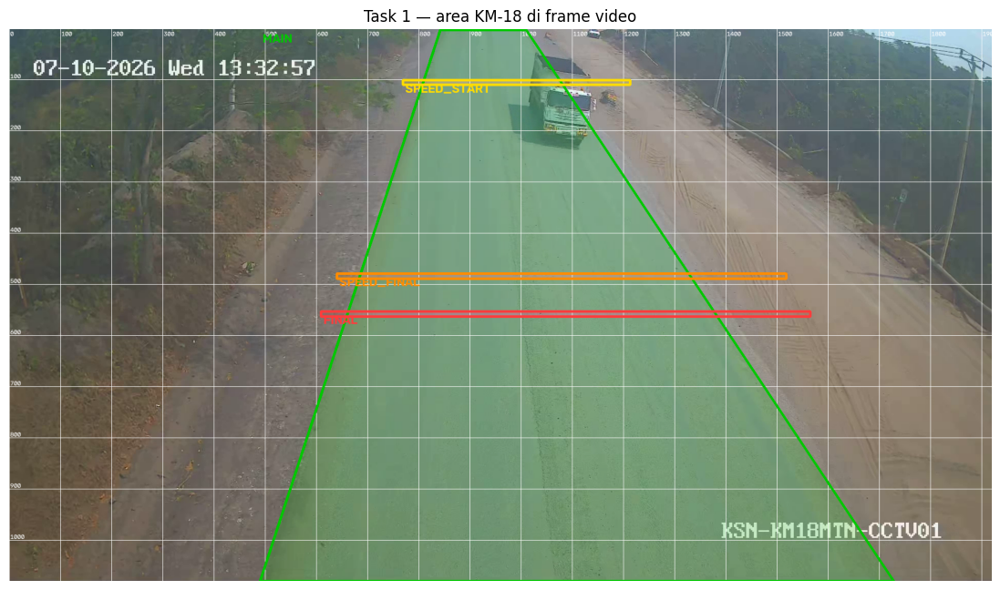

In [ ]:

AREA_COLORS = {'main': (0,200,0), 'speed_start': (0,220,255), 'speed_final': (0,140,255), 'final': (60,60,255)}

def draw_area_preview(frame, areas, grid=100):
    img = frame.copy(); ov = img.copy()
    for name, polys in areas.polygons.items():
        for p in polys: cv2.fillPoly(ov, [p.reshape(-1,1,2)], AREA_COLORS[name])
    img = cv2.addWeighted(ov, 0.18, img, 0.82, 0)
    for x in range(0, img.shape[1], grid):
        cv2.line(img, (x,0), (x,img.shape[0]), (255,255,255), 1); cv2.putText(img, str(x), (x+2,15), 0, 0.4, (255,255,255), 1)
    for y in range(0, img.shape[0], grid):
        cv2.line(img, (0,y), (img.shape[1],y), (255,255,255), 1); cv2.putText(img, str(y), (2,y-2), 0, 0.4, (255,255,255), 1)
    for name, polys in areas.polygons.items():
        for p in polys:
            cv2.polylines(img, [p.reshape(-1,1,2)], True, AREA_COLORS[name], 3)
            cv2.putText(img, name.upper(), tuple(int(v) for v in p.min(0)+[5,25]), 0, 0.8, AREA_COLORS[name], 2)
    return img

frame0 = read_frame(VIDEO, int(FPS * 1))
show(draw_area_preview(frame0, areas), 'Task 1 — area KM-18 di frame video')

In [ ]:

for name, polys in areas.polygons.items():
    c = tuple(polys[0].mean(0))
    print(f'{name:12s} centroid={tuple(round(v) for v in c)} ->', {k: v for k, v in areas.areas_of(c).items() if v})

main         centroid=(1018, 542) -> {'main': True}
speed_start  centroid=(991, 106) -> {'main': True, 'speed_start': True}
speed_final  centroid=(1079, 484) -> {'main': True, 'speed_final': True}
final        centroid=(1087, 558) -> {'main': True, 'final': True}


---
## 3. Deteksi Kendaraan (detection + multi-object tracking)



In [ ]:
%%writefile hauling_offline/detector.py

from __future__ import annotations

import os
import tempfile
from dataclasses import dataclass
from pathlib import Path
from typing import List, Optional, Sequence

import numpy as np


os.environ.setdefault("YOLO_OFFLINE", "1")

COCO_VEHICLE_NAMES = {"car", "motorcycle", "bus", "truck"}


@dataclass(frozen=True)
class Detection:
    track_id: Optional[int]
    bbox_xyxy: tuple
    confidence: float
    class_id: int
    class_name: str = "Vehicle"


def model_train_args(yolo_model) -> dict:
    """train_args yang tersimpan di checkpoint Ultralytics (imgsz, single_cls, dll)."""
    ckpt = getattr(yolo_model, "ckpt", None) or {}
    args = ckpt.get("train_args") if isinstance(ckpt, dict) else None
    return dict(args or {})


def auto_vehicle_classes(names: dict, train_args: Optional[dict] = None) -> Optional[List[int]]:
    """Tentukan filter kelas untuk model vehicle.

    - Model dilatih single_cls (mis. Hauling_Vehicle_yolov8m_SingleCls_*): SEMUA deteksi keluar sebagai
      kelas 0, walau names berisi 5 nama -> jangan difilter (None).
    - Ada kelas bernama persis 'vehicle' -> pakai kelas itu.
    - Model COCO -> car/motorcycle/bus/truck.
    - Lainnya -> semua kelas.
    """
    if (train_args or {}).get("single_cls"):
        return None
    lower = {int(i): str(n).strip().lower() for i, n in names.items()}
    exact = [i for i, n in lower.items() if n == "vehicle"]
    if exact:
        return exact
    coco = [i for i, n in lower.items() if n in COCO_VEHICLE_NAMES]
    if len(coco) == len(COCO_VEHICLE_NAMES) and len(lower) >= 80:
        return coco
    return None


def write_tracker_yaml(track_buffer_frames: int, out_dir: Path, tracker: str = "bytetrack") -> Path:
    """Buat file tracker custom dengan track_buffer sesuai fps (toleransi occlusion pendek)."""
    import ultralytics
    base = Path(ultralytics.__file__).parent / "cfg" / "trackers" / f"{tracker}.yaml"
    lines = []
    for line in base.read_text(encoding="utf-8").splitlines():
        if line.strip().startswith("track_buffer:"):
            line = f"track_buffer: {int(track_buffer_frames)}"
        lines.append(line)
    out_dir.mkdir(parents=True, exist_ok=True)
    out = out_dir / f"{tracker}_hauling.yaml"
    out.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return out


class VehicleTracker:
    """Jalankan model vehicle + tracking per frame. Hasilnya list Detection ber-track_id."""

    def __init__(
        self,
        model_path: str,
        conf: float = 0.25,
        iou: float = 0.5,
        imgsz: Optional[int] = None,
        max_det: int = 100,
        device: Optional[str] = None,
        classes: Optional[Sequence[int]] = None,
        track_buffer_frames: int = 60,
        tracker: str = "bytetrack",
    ):
        from ultralytics import YOLO
        self.model = YOLO(model_path)
        self.names = self.model.names if isinstance(self.model.names, dict) else dict(enumerate(self.model.names))
        self.train_args = model_train_args(self.model)
        if imgsz is None:
            imgsz = self.train_args.get("imgsz") or 640
        self.conf, self.iou, self.imgsz, self.max_det, self.device = conf, iou, int(imgsz), int(max_det), device
        self.classes = list(classes) if classes is not None else auto_vehicle_classes(self.names, self.train_args)
        tmp = Path(tempfile.mkdtemp(prefix="hauling_trk_"))
        self.tracker_cfg = str(write_tracker_yaml(track_buffer_frames, tmp, tracker))

    def track(self, frame: np.ndarray) -> List[Detection]:
        kwargs = dict(
            persist=True, tracker=self.tracker_cfg, conf=self.conf, iou=self.iou,
            imgsz=self.imgsz, max_det=self.max_det, classes=self.classes, verbose=False,
        )
        if self.device:
            kwargs["device"] = self.device
        res = self.model.track(frame, **kwargs)[0]
        boxes = res.boxes
        if boxes is None or len(boxes) == 0:
            return []
        xyxy = boxes.xyxy.cpu().numpy()
        conf = boxes.conf.cpu().numpy()
        cls = boxes.cls.cpu().numpy().astype(int)
        ids = boxes.id.cpu().numpy().astype(int) if boxes.id is not None else [None] * len(xyxy)
        return [
            Detection(
                track_id=(int(t) if t is not None else None),
                bbox_xyxy=tuple(float(v) for v in b),
                confidence=round(float(c), 4),
                class_id=int(k),
            )
            for b, c, k, t in zip(xyxy, conf, cls, ids)
        ]

Overwriting hauling_offline/detector.py


In [ ]:
import hauling_offline.detector as D; importlib.reload(D)

if 'cfg' not in globals() or 'areas' not in globals():
    raise RuntimeError('Config area belum dimuat. Jalankan dulu bagian 1 berurutan: 1.0 -> 1a -> 1b -> 1c -> 1d.')

def make_tracker():
    mp = cfg.model_params
    return D.VehicleTracker(str(VEHICLE_MODEL), conf=mp.get('conf', 0.25), iou=mp.get('iou', 0.5),
                            imgsz=int(mp['imgsz']) if 'imgsz' in mp else None, max_det=int(mp.get('max_det', 100)),
                            device=DEVICE, track_buffer_frames=int(2.0 * FPS))

tracker = make_tracker()
print('Kelas model:', tracker.names)
print('single_cls :', tracker.train_args.get('single_cls'), '| imgsz:', tracker.imgsz)
print('Filter kelas:', tracker.classes, '(None = semua kelas; benar untuk model single_cls)')

Kelas model: {0: 'Truck', 1: 'Light Vehicle', 2: 'Motorcycle', 3: 'Bus', 4: 'Grader'}
single_cls : True | imgsz: 640
Filter kelas: None (None = semua kelas; benar untuk model single_cls)


600 frame | unique track: 3 | track di main area: 3 | deteksi tanpa id: 0
Frame per track: {1: 133, 3: 246, 4: 156}


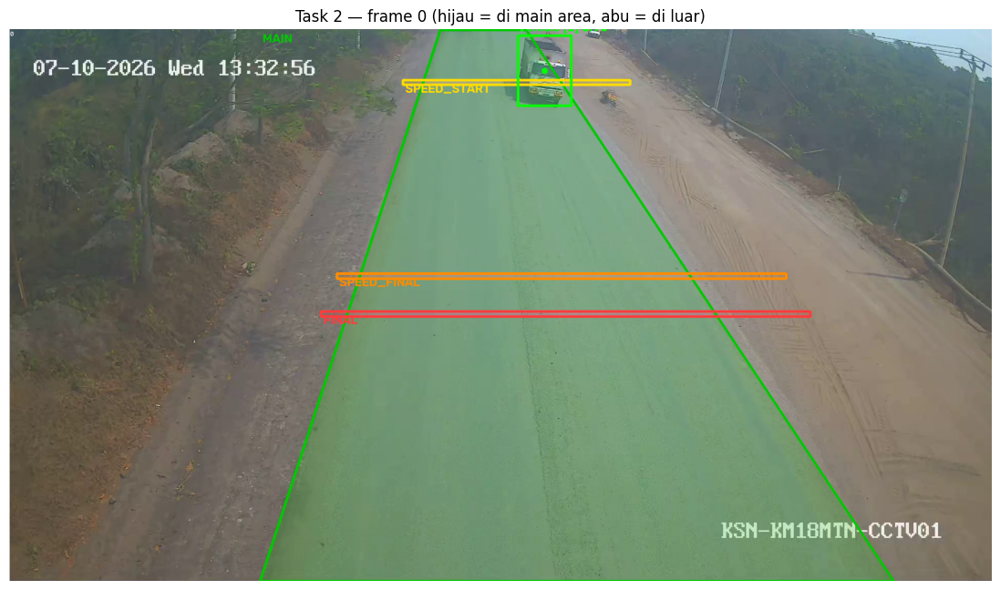

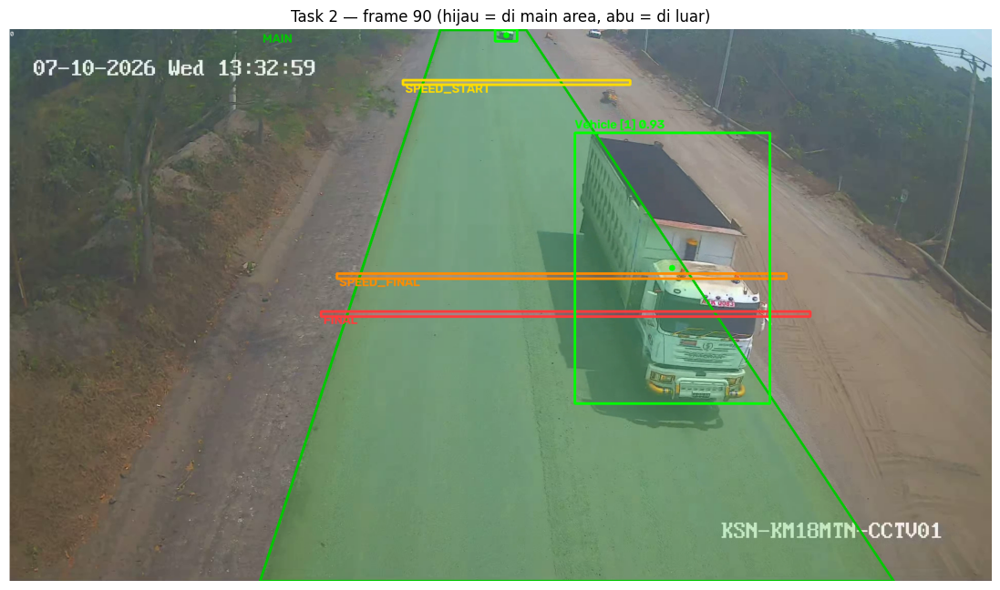

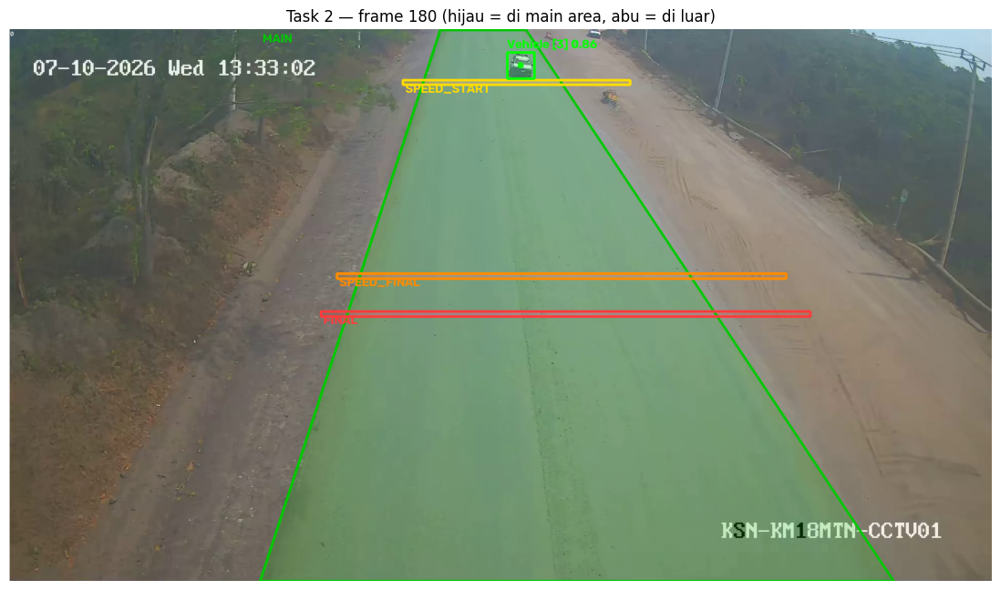

In [ ]:

from collections import defaultdict
tracker = make_tracker()
cap = cv2.VideoCapture(str(VIDEO))
track_frames, track_in_main, no_id, samples = defaultdict(int), set(), 0, []
n_demo = int(DEMO_SECONDS * FPS)
for fi in range(n_demo):
    ok, frame = cap.read()
    if not ok: break
    dets = tracker.track(frame)
    for d in dets:
        if d.track_id is None: no_id += 1; continue
        track_frames[d.track_id] += 1
        if areas.contains('main', G.bbox_center(d.bbox_xyxy)): track_in_main.add(d.track_id)
    if dets and len(samples) < 3 and fi % int(FPS * 3) == 0:
        img = draw_area_preview(frame, areas, grid=10_000)
        for d in dets:
            x1, y1, x2, y2 = map(int, d.bbox_xyxy); cx, cy = map(int, G.bbox_center(d.bbox_xyxy))
            inside = areas.contains('main', (cx, cy)); col = (0,255,0) if inside else (160,160,160)
            cv2.rectangle(img, (x1,y1), (x2,y2), col, 3); cv2.circle(img, (cx,cy), 6, col, -1)
            cv2.putText(img, f'Vehicle [{d.track_id}] {d.confidence:.2f}', (x1, y1-8), 0, 0.8, col, 2)
        samples.append((fi, img))
cap.release()
print(f'{fi+1} frame | unique track: {len(track_frames)} | track di main area: {len(track_in_main)} | deteksi tanpa id: {no_id}')
print('Frame per track:', dict(sorted(track_frames.items())))
for fi, img in samples: show(img, f'Task 2 — frame {fi} (hijau = di main area, abu = di luar)')

> **Tuning:** bila banyak ID berganti (ID switch) naikkan `track_buffer_sec`; bila banyak false positive naikkan `conf`.
> Semua bisa dioverride dari CLI (`--conf --iou --imgsz --max-det --track-buffer-sec`).

---
## 4. Logic Speed Detection



In [ ]:
%%writefile hauling_offline/speed.py
"""TASK 3 - Logic Speed Detection: kalkulator speed murni (tanpa I/O).

speed_kmh = (distance_meter / elapsed_seconds) x 3.6
Timestamp WAJIB berasal dari clock video (frame_index / fps), bukan time.time().
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Optional


STATUS_VALID = "valid"
STATUS_NOT_CROSSED_START = "not_crossed_start"
STATUS_NOT_CROSSED_FINISH = "not_crossed_finish"
STATUS_WRONG_ORDER = "wrong_order"
STATUS_STARTED_IN_FINISH = "started_in_finish"
STATUS_INVALID_ELAPSED = "invalid_elapsed_time"

TS_DECIMALS = 6
SPEED_DECIMALS = 2


def video_timestamp(frame_index: int, fps: float) -> float:
    """Clock video: frame_index / fps (deterministik untuk input yang sama)."""
    if fps <= 0:
        raise ValueError("fps harus > 0")
    return frame_index / fps


@dataclass(frozen=True)
class SpeedResult:
    status: str
    elapsed_seconds: Optional[float]
    speed_kmh: Optional[float]
    is_overspeed: Optional[bool]

    @property
    def valid(self) -> bool:
        return self.status == STATUS_VALID


def compute_speed(
    start_ts: Optional[float],
    end_ts: Optional[float],
    distance_meter: float,
    speed_limit_kmh: float,
    started_in_finish: bool = False,
    finish_before_start: bool = False,
) -> SpeedResult:
    """Validasi urutan crossing lalu hitung speed. Speed None bila tidak valid."""
    if start_ts is None:
        return SpeedResult(STATUS_NOT_CROSSED_START, None, None, None)
    if started_in_finish:
        return SpeedResult(STATUS_STARTED_IN_FINISH, None, None, None)
    if end_ts is None:
        return SpeedResult(STATUS_NOT_CROSSED_FINISH, None, None, None)
    if finish_before_start or end_ts < start_ts:
        return SpeedResult(STATUS_WRONG_ORDER, None, None, None)

    elapsed = round(end_ts - start_ts, TS_DECIMALS)
    if elapsed <= 0:
        return SpeedResult(STATUS_INVALID_ELAPSED, None, None, None)

    speed = round((distance_meter / elapsed) * 3.6, SPEED_DECIMALS)
    return SpeedResult(STATUS_VALID, elapsed, speed, speed > speed_limit_kmh)

Overwriting hauling_offline/speed.py


In [ ]:
%%writefile hauling_offline/tracks.py
"""State machine per track_id — sumber kebenaran untuk area, speed, arah, plat, dan event.

Alur per frame (dipanggil oleh pipeline):
    1. observe(detections, frame_index, ts)  -> update area/arah; return track yang butuh deteksi plat
    2. add_plate(track_id, candidate)        -> simpan kandidat plat terbaik
    3. collect_events(...)                   -> event untuk track yang baru mencapai final area (maks. 1x)
"""
from __future__ import annotations

import logging
from dataclasses import dataclass, field
from typing import TYPE_CHECKING, Dict, List, Optional, Sequence, Tuple

from .detector import Detection
from .geometry import AreaSet, bbox_center
from .speed import SpeedResult, compute_speed

if TYPE_CHECKING:
    from .plate import PlateCandidate

log = logging.getLogger("hauling.tracks")


@dataclass
class TrackState:
    track_id: int
    first_seen_frame: int
    last_seen_frame: int
    in_main_seen: bool = False
    first_main_centroid: Optional[Tuple[float, float]] = None
    last_centroid: Optional[Tuple[float, float]] = None
    last_main_frame: Optional[int] = None
    max_confidence: float = 0.0
    last_confidence: float = 0.0
    # speed
    speed_start_ts: Optional[float] = None
    speed_start_frame: Optional[int] = None
    speed_end_ts: Optional[float] = None
    speed_end_frame: Optional[int] = None
    started_in_finish: bool = False
    finish_before_start: bool = False
    # plate
    best_plate: Optional["PlateCandidate"] = None
    plate_errors: int = 0
    # OCR nomor lambung (opsional): voting teks antar-frame
    ocr_scores: Dict[str, float] = field(default_factory=dict)
    ocr_reads: int = 0
    ocr_attempts: int = 0
    # event
    reached_final_frame: Optional[int] = None
    reached_final_ts: Optional[float] = None
    event_written: bool = False
    notes: List[str] = field(default_factory=list)

    def lambung_text(self) -> Optional[str]:
        if not self.ocr_scores:
            return None
        return max(self.ocr_scores.items(), key=lambda kv: (round(kv[1], 6), len(kv[0]), kv[0]))[0]

    def speed(self, distance_meter: float, speed_limit_kmh: float) -> SpeedResult:
        return compute_speed(
            self.speed_start_ts, self.speed_end_ts, distance_meter, speed_limit_kmh,
            started_in_finish=self.started_in_finish, finish_before_start=self.finish_before_start,
        )


@dataclass
class VehicleEvent:
    """Satu baris events.csv (sebelum diformat)."""
    track_id: int
    event_timestamp_s: float
    event_frame_index: int
    travel_direction: str
    vehicle_confidence: float
    speed_start_timestamp_s: Optional[float]
    speed_end_timestamp_s: Optional[float]
    distance_meter: float
    speed_limit_kmh: float
    speed: SpeedResult
    plate: Optional["PlateCandidate"]
    notes: str = ""
    plate_text: str = ""


class TrackManager:
    def __init__(
        self,
        areas: AreaSet,
        distance_meter: float,
        speed_limit_kmh: float,
        down_direction: str = "South",
        min_move_ratio: float = 0.02,
        max_gap_frames: int = 10,
    ):
        self.areas = areas
        self.distance_meter = distance_meter
        self.speed_limit_kmh = speed_limit_kmh
        self.down_direction = down_direction
        self.up_direction = {"South": "North", "North": "South"}.get(down_direction, "Unknown")
        self.min_move_px = max(1.0, min_move_ratio * areas.frame_res[1])
        self.tracks: Dict[int, TrackState] = {}
        self.detections_without_id = 0
        self.max_gap_frames = max_gap_frames

    # ------------------------------------------------------------------ #
    def direction_of(self, st: TrackState) -> str:
        """Arah sederhana dari perubahan centroid (sumbu y frame)."""
        if st.first_main_centroid is None or st.last_centroid is None:
            return "Unknown"
        dy = st.last_centroid[1] - st.first_main_centroid[1]
        if abs(dy) < self.min_move_px:
            return "Unknown"
        return self.down_direction if dy > 0 else self.up_direction

    def observe(self, detections: Sequence[Detection], frame_index: int, ts: float) -> List[Detection]:
        """Update state semua track. Return deteksi (dalam main area, event belum ditulis) untuk plate detection."""
        need_plate: List[Detection] = []
        for det in detections:
            if det.track_id is None:
                self.detections_without_id += 1
                continue
            tid = det.track_id
            st = self.tracks.get(tid)
            if st is None:
                st = self.tracks[tid] = TrackState(tid, frame_index, frame_index)
            st.last_seen_frame = frame_index
            st.last_confidence = det.confidence
            st.max_confidence = max(st.max_confidence, det.confidence)
            c = bbox_center(det.bbox_xyxy)

            if st.event_written:
                continue
            if not self.areas.contains("main", c):
                continue

            prev = st.last_centroid if (st.last_main_frame is not None and
                                        frame_index - st.last_main_frame <= self.max_gap_frames) else None
            st.last_centroid, st.last_main_frame = c, frame_index

            in_start = self.areas.touches("speed_start", c, prev)
            in_finish = self.areas.touches("speed_final", c, prev)
            in_final = self.areas.touches("final", c, prev)

            if not st.in_main_seen:
                st.in_main_seen = True
                st.first_main_centroid = c
                if in_finish and not in_start:
                    st.started_in_finish = True
                    st.notes.append("first_seen_in_speed_final")
                    log.info("track %s first seen inside speed-final area (f=%d)", tid, frame_index)

            if in_start and st.speed_start_ts is None:
                st.speed_start_ts, st.speed_start_frame = ts, frame_index
                if st.speed_end_ts is not None:
                    st.finish_before_start = True
                log.info("track %s entered_start t=%.3fs f=%d", tid, ts, frame_index)

            if in_finish and st.speed_end_ts is None:
                st.speed_end_ts, st.speed_end_frame = ts, frame_index
                if st.speed_start_ts is None:
                    st.finish_before_start = True
                log.info("track %s entered_finish t=%.3fs f=%d", tid, ts, frame_index)

            if in_final and st.reached_final_frame is None:
                st.reached_final_frame, st.reached_final_ts = frame_index, ts

            need_plate.append(det)
        return need_plate

    def add_plate(self, track_id: int, cand: Optional["PlateCandidate"]) -> None:
        from .plate import better_plate
        st = self.tracks.get(track_id)
        if st is not None and not st.event_written:
            st.best_plate = better_plate(st.best_plate, cand)

    def add_ocr(self, track_id: int, text: Optional[str], conf: float = 1.0) -> None:
        """Tambahkan 1 vote hasil baca nomor lambung (None = percobaan gagal)."""
        st = self.tracks.get(track_id)
        if st is None or st.event_written:
            return
        st.ocr_attempts += 1
        if text:
            st.ocr_scores[text] = st.ocr_scores.get(text, 0.0) + conf
            st.ocr_reads += 1

    def mark_plate_error(self, track_id: int) -> None:
        st = self.tracks.get(track_id)
        if st is not None:
            st.plate_errors += 1

    def collect_events(self) -> List[VehicleEvent]:
        """Event untuk track yang sudah mencapai final area dan belum pernah ditulis (anti-duplikasi)."""
        events: List[VehicleEvent] = []
        for st in self.tracks.values():
            if st.event_written or st.reached_final_frame is None:
                continue
            st.event_written = True
            sp = st.speed(self.distance_meter, self.speed_limit_kmh)
            notes = list(st.notes)
            if st.plate_errors:
                notes.append(f"plate_detector_errors={st.plate_errors}")
            if st.ocr_attempts:
                notes.append(f"ocr_reads={st.ocr_reads}/{st.ocr_attempts}")
            events.append(VehicleEvent(
                track_id=st.track_id,
                event_timestamp_s=st.reached_final_ts,
                event_frame_index=st.reached_final_frame,
                travel_direction=self.direction_of(st),
                vehicle_confidence=st.max_confidence,
                speed_start_timestamp_s=st.speed_start_ts,
                speed_end_timestamp_s=st.speed_end_ts,
                distance_meter=self.distance_meter,
                speed_limit_kmh=self.speed_limit_kmh,
                speed=sp,
                plate=st.best_plate,
                notes=";".join(notes),
                plate_text=st.lambung_text() or "",
            ))
            log.info("track %s event_written t=%.3fs status=%s speed=%s", st.track_id,
                     st.reached_final_ts, sp.status, sp.speed_kmh)
        return events


    def lost_before_final(self) -> List[int]:
        """Track yang masuk main area tetapi tidak pernah mencapai final area (tidak ditulis paksa)."""
        return sorted(t for t, s in self.tracks.items() if s.in_main_seen and not s.event_written)

    def live_speed(self, track_id: int) -> Optional[SpeedResult]:
        st = self.tracks.get(track_id)
        if st is None:
            return None
        return st.speed(self.distance_meter, self.speed_limit_kmh)

Overwriting hauling_offline/tracks.py


In [ ]:
import hauling_offline.speed as S, hauling_offline.tracks as T
importlib.reload(S); importlib.reload(T)


for start, end in [(10.0, 13.0), (10.0, 12.0), (10.0, None), (None, 12.0), (12.0, 10.0), (5.0, 5.0)]:
    r = S.compute_speed(start, end, cfg.distance_meter, cfg.speed_limit_kmh)
    print(f'start={start!s:5} end={end!s:5} -> status={r.status:22s} elapsed={r.elapsed_seconds} speed={r.speed_kmh} overspeed={r.is_overspeed}')

start=10.0  end=13.0  -> status=valid                  elapsed=3.0 speed=56.4 overspeed=False
start=10.0  end=12.0  -> status=valid                  elapsed=2.0 speed=84.6 overspeed=True
start=10.0  end=None  -> status=not_crossed_finish     elapsed=None speed=None overspeed=None
start=None  end=12.0  -> status=not_crossed_start      elapsed=None speed=None overspeed=None
start=12.0  end=10.0  -> status=wrong_order            elapsed=None speed=None overspeed=None
start=5.0   end=5.0   -> status=invalid_elapsed_time   elapsed=None speed=None overspeed=None


In [ ]:

import logging, pandas as pd
logging.basicConfig(level=logging.INFO, format='%(message)s', force=True)

tracker = make_tracker()
manager = T.TrackManager(areas, cfg.distance_meter, cfg.speed_limit_kmh, down_direction='South')
cap = cv2.VideoCapture(str(VIDEO)); events = []
for fi in range(int(DEMO_SECONDS * FPS)):
    ok, frame = cap.read()
    if not ok: break
    ts = S.video_timestamp(fi, FPS)
    manager.observe(tracker.track(frame), fi, ts)
    events += manager.collect_events()
cap.release()

rows = []
for tid, st in manager.tracks.items():
    if not st.in_main_seen: continue
    sp = st.speed(cfg.distance_meter, cfg.speed_limit_kmh)
    rows.append(dict(track_id=tid, start_ts=st.speed_start_ts, finish_ts=st.speed_end_ts, elapsed=sp.elapsed_seconds,
                     speed_kmh=sp.speed_kmh, status=sp.status, overspeed=sp.is_overspeed,
                     direction=manager.direction_of(st), event_written=st.event_written))
print(f'\nEvent tertulis: {len(events)} | track hilang sebelum final: {manager.lost_before_final()}')
pd.DataFrame(rows)

track 1 entered_start t=0.400s f=12
track 1 entered_finish t=3.033s f=91
track 1 event_written t=3.200s status=valid speed=64.25
track 3 entered_start t=6.800s f=204
track 3 entered_finish t=9.833s f=295
track 3 event_written t=10.033s status=valid speed=55.78
track 4 entered_start t=18.967s f=569



Event tertulis: 2 | track hilang sebelum final: [4]


,track_id,start_ts,finish_ts,elapsed,speed_kmh,status,overspeed,direction,event_written
0,1,0.400000,3.033333,2.633333,64.25,valid,True,South,True
1,3,6.800000,9.833333,3.033333,55.78,valid,False,South,True
2,4,18.966667,NaN,NaN,NaN,not_crossed_finish,None,South,False


---
## 5. Deteksi Nomor Lambung (di atas kaca depan)



In [ ]:
%%writefile hauling_offline/plate.py

from __future__ import annotations

from dataclasses import dataclass
from typing import List, Optional, Sequence, Tuple

import numpy as np


@dataclass(frozen=True)
class PlateCandidate:
    confidence: float
    bbox_xyxy: Tuple[int, int, int, int]   # relatif terhadap FRAME (bukan crop)
    timestamp_s: float
    frame_index: int


def better_plate(current: Optional[PlateCandidate], new: Optional[PlateCandidate]) -> Optional[PlateCandidate]:
    """Confidence tertinggi menang; bila sama, timestamp lebih akhir menang."""
    if new is None:
        return current
    if current is None:
        return new
    if new.confidence > current.confidence:
        return new
    if new.confidence == current.confidence and new.timestamp_s >= current.timestamp_s:
        return new
    return current


def select_best(candidates: Sequence[PlateCandidate]) -> Optional[PlateCandidate]:
    best: Optional[PlateCandidate] = None
    for c in candidates:
        best = better_plate(best, c)
    return best


def crop_with_offset(frame: np.ndarray, xyxy: Sequence[float], pad: float = 0.0):
    """Potong bbox kendaraan dari frame. Return (crop, (ox, oy)) atau (None, None) bila crop kosong."""
    h, w = frame.shape[:2]
    x1, y1, x2, y2 = xyxy
    pw, ph = (x2 - x1) * pad, (y2 - y1) * pad
    x1 = int(max(0, np.floor(x1 - pw)))
    y1 = int(max(0, np.floor(y1 - ph)))
    x2 = int(min(w, np.ceil(x2 + pw)))
    y2 = int(min(h, np.ceil(y2 + ph)))
    if x2 - x1 < 4 or y2 - y1 < 4:
        return None, None
    return frame[y1:y2, x1:x2], (x1, y1)


def sub_region(xyxy: Sequence[float], region: Sequence[float]) -> Tuple[float, float, float, float]:
    """Ambil sub-bagian bbox kendaraan. region = (y0, y1, x0, x1) dalam fraksi 0..1 dari bbox.

    Contoh: (0.4, 1.0, 0.25, 1.0) = area kabin truk yang menghadap kamera, tempat nomor lambung di atas kaca.
    """
    y0, y1, x0, x1 = region
    if not (0 <= y0 < y1 <= 1 and 0 <= x0 < x1 <= 1):
        raise ValueError(f"plate region tidak valid: {region} (format y0,y1,x0,x1 dalam 0..1)")
    bx1, by1, bx2, by2 = xyxy
    w, h = bx2 - bx1, by2 - by1
    return bx1 + x0 * w, by1 + y0 * h, bx1 + x1 * w, by1 + y1 * h


def merge_parts(boxes: Sequence[Tuple[float, float, float, float, float]], gap_ratio: float = 1.0):
    """Gabungkan potongan nomor lambung (blok 'huruf' + blok 'angka') menjadi 1 bbox.

    boxes: list (x1, y1, x2, y2, conf). Anchor = box confidence tertinggi; box lain digabung bila
    sejajar vertikal (overlap tinggi >= 30%) dan jarak horizontal <= gap_ratio x tinggi anchor.
    Return (x1, y1, x2, y2, conf_anchor) atau None.
    """
    if not boxes:
        return None
    order = sorted(boxes, key=lambda b: b[4], reverse=True)
    ax1, ay1, ax2, ay2, aconf = order[0]
    merged = [ax1, ay1, ax2, ay2]
    changed = True
    rest = list(order[1:])
    while changed:
        changed = False
        for b in list(rest):
            x1, y1, x2, y2, _ = b
            h_ref = max(1e-6, min(merged[3] - merged[1], y2 - y1))
            v_overlap = max(0.0, min(merged[3], y2) - max(merged[1], y1)) / h_ref
            h_gap = max(0.0, max(merged[0], x1) - min(merged[2], x2))
            if v_overlap >= 0.3 and h_gap <= gap_ratio * (ay2 - ay1):
                merged = [min(merged[0], x1), min(merged[1], y1), max(merged[2], x2), max(merged[3], y2)]
                rest.remove(b)
                changed = True
    return merged[0], merged[1], merged[2], merged[3], aconf


class PlateDetector:
    """Adapter model nomor lambung (Ultralytics YOLO). Dijalankan pada crop kendaraan, bukan full frame.

    merge='best'  -> ambil 1 box confidence tertinggi (model yang langsung mendeteksi plat utuh)
    merge='union' -> gabungkan potongan plat (model 'huruf'/'angka' seperti detection_hauling_angka_huruf_V1)
    merge='auto'  -> 'union' bila nama kelas berisi huruf/angka/character, selain itu 'best'
    """

    def __init__(
        self,
        model_path: str,
        conf: float = 0.25,
        imgsz: Optional[int] = None,
        device: Optional[str] = None,
        region: Sequence[float] = (0.0, 1.0, 0.0, 1.0),
        merge: str = "auto",
        classes: Optional[Sequence[int]] = None,
    ):
        from ultralytics import YOLO  # import lokal agar unit test tidak butuh ultralytics
        from .detector import model_train_args
        self.model = YOLO(model_path)
        self.names = self.model.names if isinstance(self.model.names, dict) else dict(enumerate(self.model.names))
        self.train_args = model_train_args(self.model)
        self.conf = conf
        self.imgsz = int(imgsz or self.train_args.get("imgsz") or 640)
        self.device = device
        self.region = tuple(float(v) for v in region)
        sub_region((0, 0, 1, 1), self.region)  # validasi
        if merge == "auto":
            lowered = " ".join(str(n).lower() for n in self.names.values())
            merge = "union" if any(k in lowered for k in ("huruf", "angka", "character")) else "best"
        if merge not in ("best", "union"):
            raise ValueError("merge harus auto/best/union")
        self.merge = merge
        self.classes = list(classes) if classes is not None else None

    def detect_on_crops(
        self,
        frame: np.ndarray,
        vehicle_boxes: Sequence[Sequence[float]],
        timestamp_s: float,
        frame_index: int,
    ) -> List[Optional[PlateCandidate]]:
        """Satu hasil per vehicle box: kandidat plat terbaik pada crop itu (atau None)."""
        crops, offsets, idx_map = [], [], []
        for i, box in enumerate(vehicle_boxes):
            crop, off = crop_with_offset(frame, sub_region(box, self.region))
            if crop is not None:
                crops.append(crop)
                offsets.append(off)
                idx_map.append(i)

        out: List[Optional[PlateCandidate]] = [None] * len(vehicle_boxes)
        if not crops:
            return out

        kwargs = dict(conf=self.conf, imgsz=self.imgsz, verbose=False, classes=self.classes)
        if self.device:
            kwargs["device"] = self.device
        results = self.model.predict(crops, **kwargs)

        for res, (ox, oy), i in zip(results, offsets, idx_map):
            if res.boxes is None or len(res.boxes) == 0:
                continue
            confs = res.boxes.conf.cpu().numpy()
            xyxy = res.boxes.xyxy.cpu().numpy()
            raw = [(float(b[0]), float(b[1]), float(b[2]), float(b[3]), float(c)) for b, c in zip(xyxy, confs)]
            if self.merge == "union":
                m = merge_parts(raw)
                picks = [m] if m else []
            else:
                picks = raw
            cands = [
                PlateCandidate(
                    confidence=round(c, 4),
                    bbox_xyxy=(int(round(x1 + ox)), int(round(y1 + oy)), int(round(x2 + ox)), int(round(y2 + oy))),
                    timestamp_s=timestamp_s,
                    frame_index=frame_index,
                )
                for x1, y1, x2, y2, c in picks
            ]
            out[i] = select_best(cands)
        return out

Overwriting hauling_offline/plate.py


crop sampel: [0, 30, 60, 120]


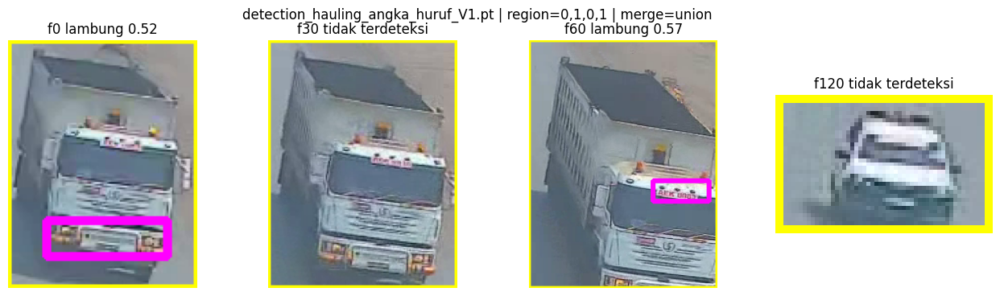

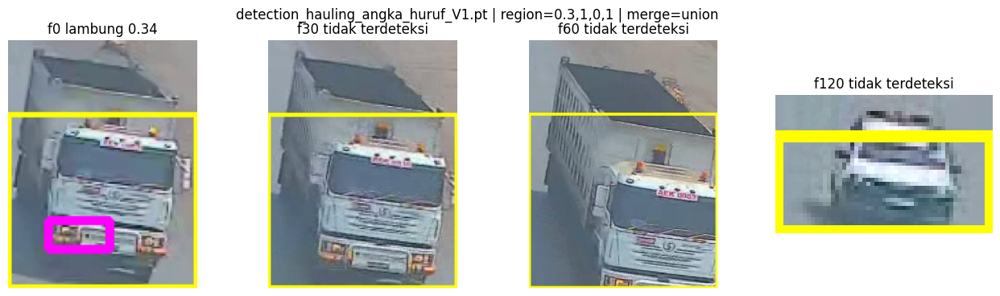

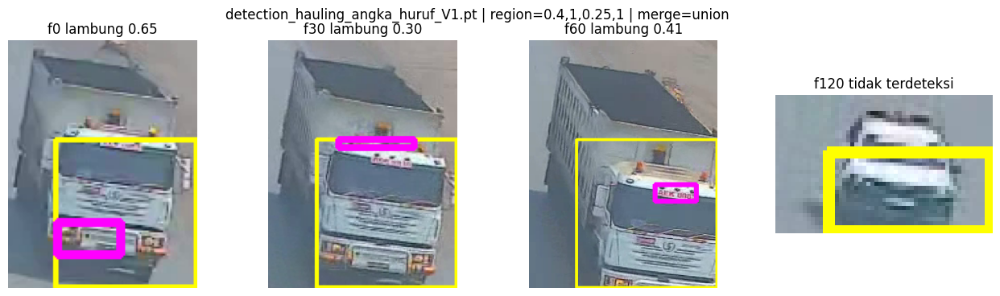

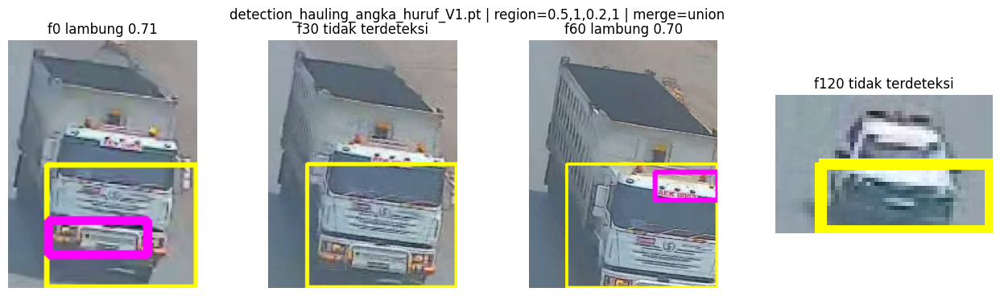

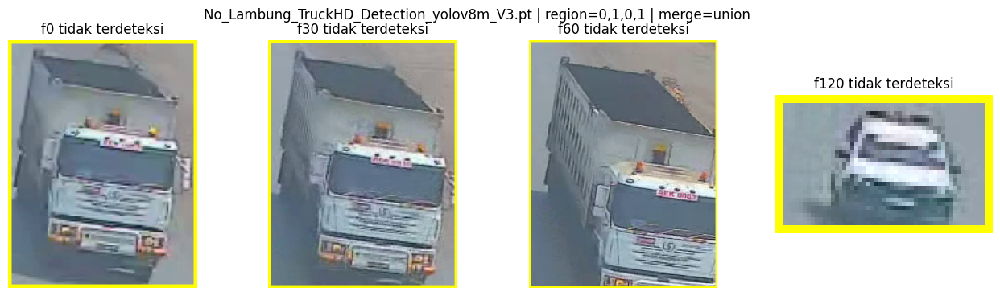

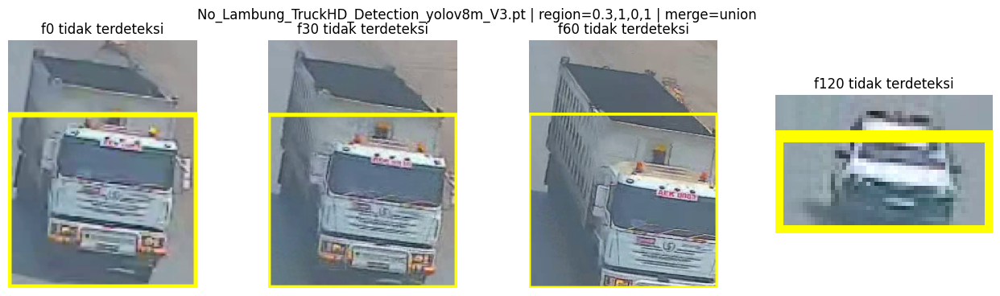

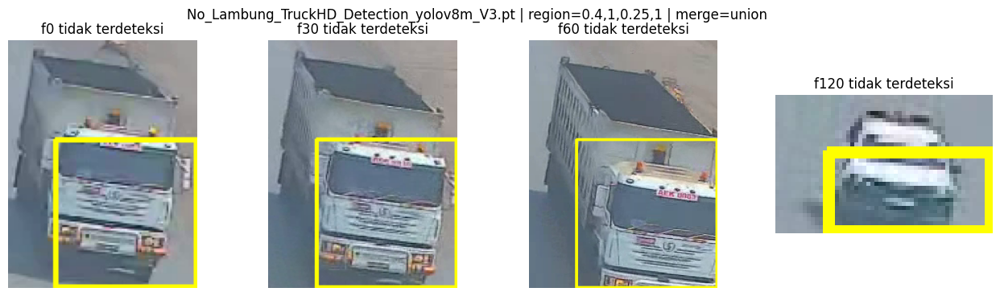

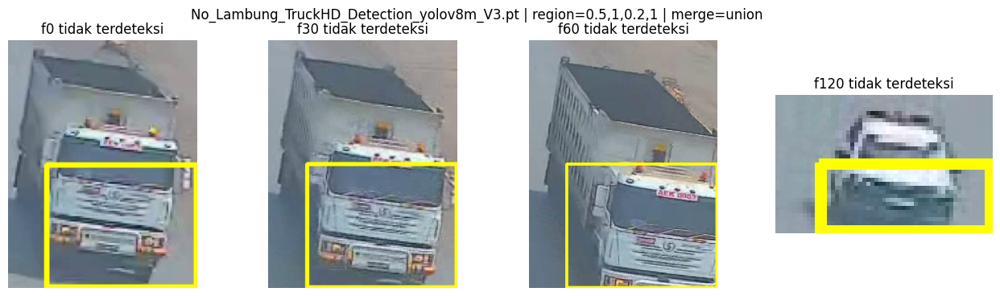

In [ ]:

import hauling_offline.plate as P; importlib.reload(P)
CANDIDATES = [MODEL_DIR / 'detection_hauling_angka_huruf_V1.pt', MODEL_DIR / 'No_Lambung_TruckHD_Detection_yolov8m_V3.pt']
REGIONS = ['0,1,0,1', '0.3,1,0,1', '0.4,1,0.25,1', '0.5,1,0.2,1']


tracker = make_tracker(); cap = cv2.VideoCapture(str(VIDEO)); picks = []
for fi in range(int(DEMO_SECONDS * FPS)):
    ok, frame = cap.read()
    if not ok: break
    if fi % int(FPS) : continue
    for d in tracker.track(frame):
        if areas.contains('main', G.bbox_center(d.bbox_xyxy)) and len(picks) < 4:
            picks.append((fi, frame.copy(), d.bbox_xyxy))
cap.release()
print('crop sampel:', [p[0] for p in picks])

for mpath in CANDIDATES:
    for reg in REGIONS:
        det = P.PlateDetector(str(mpath), conf=0.25, device=DEVICE, region=[float(v) for v in reg.split(',')])
        fig, axs = plt.subplots(1, max(1, len(picks)), figsize=(4 * max(1, len(picks)), 4))
        for ax, (fi, frame, box) in zip(np.atleast_1d(axs), picks):
            c = det.detect_on_crops(frame, [box], 0.0, fi)[0]
            crop, (ox, oy) = P.crop_with_offset(frame, box); crop = crop.copy()
            rx1, ry1, rx2, ry2 = map(int, P.sub_region(box, det.region))
            cv2.rectangle(crop, (rx1-ox, ry1-oy), (rx2-ox, ry2-oy), (0,255,255), 2)        # kuning = region
            if c: cv2.rectangle(crop, (c.bbox_xyxy[0]-ox, c.bbox_xyxy[1]-oy), (c.bbox_xyxy[2]-ox, c.bbox_xyxy[3]-oy), (255,0,255), 3)
            ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); ax.axis('off')
            ax.set_title(f'f{fi} ' + (f'lambung {c.confidence:.2f}' if c else 'tidak terdeteksi'))
        fig.suptitle(f'{mpath.name} | region={reg} | merge={det.merge}'); plt.show()

Kelas model nomor lambung: {0: 'huruf', 1: 'angka'} | merge: union | imgsz: 640 | region: (0.3, 0.85, 0.25, 1.0)


track 1 entered_start t=0.400s f=12
track 1 entered_finish t=3.033s f=91
track 1 event_written t=3.200s status=valid speed=64.25
track 3 entered_start t=6.800s f=204
track 3 entered_finish t=9.833s f=295
track 3 event_written t=10.033s status=valid speed=55.78
track 4 entered_start t=18.967s f=569


Nomor lambung terbaik per track:
  track 1: conf=0.8637 bbox=[1052, 196, 1081, 215] t=1.133s
  track 3: conf=0.8133 bbox=[1153, 379, 1215, 396] t=9.600s
  track 4: conf=0.7088 bbox=[1005, 26, 1049, 30] t=17.267s


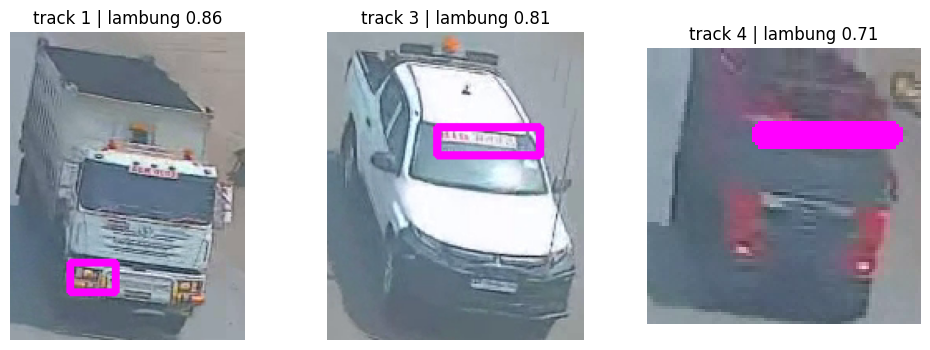

In [ ]:
importlib.reload(T)
plate_det = P.PlateDetector(str(PLATE_MODEL), conf=0.25, device=DEVICE, region=[float(v) for v in PLATE_REGION.split(',')])
print('Kelas model nomor lambung:', plate_det.names, '| merge:', plate_det.merge, '| imgsz:', plate_det.imgsz, '| region:', plate_det.region)

tracker = make_tracker(); manager = T.TrackManager(areas, cfg.distance_meter, cfg.speed_limit_kmh)
cap = cv2.VideoCapture(str(VIDEO)); shown = {}
for fi in range(int(DEMO_SECONDS * FPS)):
    ok, frame = cap.read()
    if not ok: break
    ts = S.video_timestamp(fi, FPS)
    need = manager.observe(tracker.track(frame), fi, ts)
    if not need: continue
    cands = plate_det.detect_on_crops(frame, [d.bbox_xyxy for d in need], ts, fi)
    for d, c in zip(need, cands):
        manager.add_plate(d.track_id, c)
        if c is not None and (d.track_id not in shown or c.confidence > shown[d.track_id][0].confidence):
            crop, (ox, oy) = P.crop_with_offset(frame, d.bbox_xyxy); crop = crop.copy()
            x1, y1, x2, y2 = c.bbox_xyxy
            cv2.rectangle(crop, (x1-ox, y1-oy), (x2-ox, y2-oy), (255,0,255), 3)
            shown[d.track_id] = (c, crop)
    manager.collect_events()
cap.release()

print('Nomor lambung terbaik per track:')
for tid, st in manager.tracks.items():
    if st.in_main_seen:
        bp = st.best_plate
        print(f'  track {tid}:', f'conf={bp.confidence} bbox={list(bp.bbox_xyxy)} t={bp.timestamp_s:.3f}s' if bp else 'tidak terlihat (plate_detected=false)')

items = list(shown.items())[:6]
if items:
    fig, axs = plt.subplots(1, len(items), figsize=(4 * len(items), 4))
    for ax, (tid, (c, crop)) in zip(np.atleast_1d(axs), items):
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); ax.set_title(f'track {tid} | lambung {c.confidence:.2f}'); ax.axis('off')
    plt.show()

---
## 5.1. Text Recognition Nomor Lambung


In [ ]:
%%writefile hauling_offline/ocr.py

from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np

from .plate import crop_with_offset

# (x1, x2, label, cls_conf)
Char = Tuple[float, float, str, float]

OCR_MODEL_PATTERNS = {
    "block": "detection_hauling_angka_huruf*.pt",
    "huruf_det": "character_huruf_detection*.pt",
    "angka_det": "character_angka_detection*.pt",
    "huruf_cls": "classification_hauling_huruf*.pt",
    "angka_cls": "classification_hauling_angka*.pt",
}


@dataclass(frozen=True)
class OcrResult:
    text: str          # "AEK 0078"
    huruf: str
    angka: str
    confidence: float  # rata-rata confidence klasifikasi karakter


def clean_chars(chars: Sequence[Char], min_width_ratio: float = 0.6, min_cls_conf: float = 0.6) -> List[Char]:
    """Buang karakter palsu di tepi blok: terlalu sempit (< ratio x median lebar) atau confidence klasifikasi rendah.

    Urutan hasil = kiri ke kanan.
    """
    if not chars:
        return []
    widths = [c[1] - c[0] for c in chars]
    med = float(np.median(widths))
    kept = [c for c, w in zip(chars, widths) if w >= min_width_ratio * med and c[3] >= min_cls_conf]
    return sorted(kept, key=lambda c: c[0])


def find_ocr_models(model_dir: str | Path) -> Dict[str, Path]:
    d = Path(model_dir)
    found: Dict[str, Path] = {}
    missing = []
    for key, pat in OCR_MODEL_PATTERNS.items():
        hits = sorted(d.glob(pat))
        if hits:
            found[key] = hits[-1]  # versi terakhir secara nama
        else:
            missing.append(pat)
    if missing:
        raise FileNotFoundError(f"Model OCR tidak ditemukan di {d}: {missing}")
    return found


class LambungOCR:
    def __init__(
        self,
        models: Dict[str, Path],
        device: Optional[str] = None,
        block_order: str = "position",
        pad: float = 0.15,
        block_pad: float = 0.1,
        block_conf: float = 0.25,
        char_conf: float = 0.25,
        min_cls_conf: float = 0.6,
    ):
        from ultralytics import YOLO
        self.m = {k: YOLO(str(v)) for k, v in models.items()}
        self.files = {k: Path(v).name for k, v in models.items()}
        if block_order not in ("position", "class"):
            raise ValueError("block_order harus 'position' atau 'class'")
        self.block_order, self.pad, self.block_pad = block_order, pad, block_pad
        self.block_conf, self.char_conf, self.min_cls_conf = block_conf, char_conf, min_cls_conf
        self.device = device

    def _kw(self, **kw):
        if self.device:
            kw["device"] = self.device
        kw["verbose"] = False
        return kw

    def _blocks(self, crop: np.ndarray) -> Optional[Dict[str, Tuple[int, int, int, int]]]:
        m = self.m["block"]
        r = m.predict(crop, **self._kw(imgsz=640, conf=self.block_conf))[0]
        if r.boxes is None or len(r.boxes) < 2:
            return None
        boxes = [([float(v) for v in b.xyxy[0]], float(b.conf), str(m.names[int(b.cls)]).lower()) for b in r.boxes]
        top2 = sorted(boxes, key=lambda b: -b[1])[:2]
        if self.block_order == "position":
            left, right = sorted(top2, key=lambda b: b[0][0])
            return {"huruf": tuple(map(int, left[0])), "angka": tuple(map(int, right[0]))}
        out = {name: tuple(map(int, xyxy)) for xyxy, _, name in top2}
        return out if {"huruf", "angka"} <= set(out) else None

    def _read_block(self, block: np.ndarray, kind: str) -> List[Char]:
        det, cls = self.m[f"{kind}_det"], self.m[f"{kind}_cls"]
        r = det.predict(block, **self._kw(imgsz=224, conf=self.char_conf, iou=0.5))[0]
        if r.boxes is None or len(r.boxes) == 0:
            return []
        boxes = sorted(([int(v) for v in b.xyxy[0]] for b in r.boxes), key=lambda b: b[0])
        crops = [block[max(0, y1):y2, max(0, x1):x2] for x1, y1, x2, y2 in boxes]
        keep = [(b, c) for b, c in zip(boxes, crops) if c.size > 0]
        if not keep:
            return []
        res = cls.predict([c for _, c in keep], **self._kw(imgsz=96))
        chars: List[Char] = []
        for (b, _), p in zip(keep, res):
            chars.append((b[0], b[2], str(cls.names[int(p.probs.top1)]), float(p.probs.top1conf)))
        return clean_chars(chars, min_cls_conf=self.min_cls_conf)

    def read(self, frame: np.ndarray, lambung_xyxy: Sequence[float]) -> Optional[OcrResult]:
        """Baca nomor lambung dari bbox (koordinat frame). None bila tidak terbaca lengkap."""
        crop, _ = crop_with_offset(frame, lambung_xyxy, pad=self.pad)
        if crop is None:
            return None
        blocks = self._blocks(crop)
        if not blocks:
            return None
        parts: Dict[str, List[Char]] = {}
        for kind in ("huruf", "angka"):
            blk, _ = crop_with_offset(crop, blocks[kind], pad=self.block_pad)
            if blk is None:
                return None
            parts[kind] = self._read_block(blk, kind)
        huruf = "".join(c[2] for c in parts["huruf"])
        angka = "".join(c[2] for c in parts["angka"])
        if not huruf or not angka:
            return None
        confs = [c[3] for c in parts["huruf"] + parts["angka"]]
        return OcrResult(f"{huruf} {angka}", huruf, angka, round(float(np.mean(confs)), 4))

Overwriting hauling_offline/ocr.py


Model OCR: {'block': 'detection_hauling_angka_huruf_V1.pt', 'huruf_det': 'character_huruf_detection_hauling_yolov8m_V2.pt', 'angka_det': 'character_angka_detection_hauling_yolov8m_V2.pt', 'huruf_cls': 'classification_hauling_huruf_yolo8m_imgz96_v9.pt', 'angka_cls': 'classification_hauling_angka_yolo8m_imgz96_v9.pt'}
track 1: tidak terbaca
track 3: No Lambung: HI 0  (conf karakter 0.83)
track 4: tidak terbaca


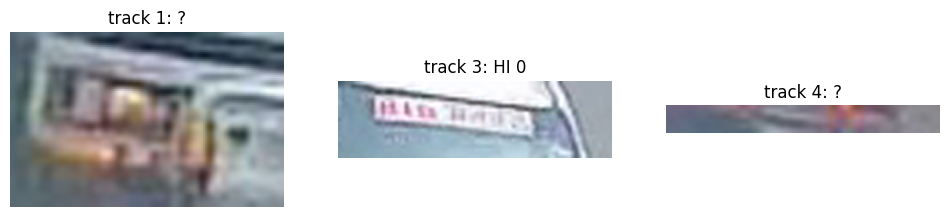

In [ ]:
import hauling_offline.ocr as O; importlib.reload(O)
ocr = O.LambungOCR(O.find_ocr_models(MODEL_DIR), device=DEVICE)
print('Model OCR:', ocr.files)
results = []
for tid, st in manager.tracks.items():
    bp = st.best_plate
    if bp is None: continue
    frame = read_frame(VIDEO, bp.frame_index)
    res = ocr.read(frame, bp.bbox_xyxy)
    crop, _ = P.crop_with_offset(frame, bp.bbox_xyxy, pad=0.15)
    results.append((tid, res, crop))
    print(f'track {tid}:', f"No Lambung: {res.text}  (conf karakter {res.confidence:.2f})" if res else 'tidak terbaca')

if results:
    fig, axs = plt.subplots(1, len(results[:6]), figsize=(4 * len(results[:6]), 2.5))
    for ax, (tid, res, crop) in zip(np.atleast_1d(axs), results[:6]):
        ax.imshow(cv2.cvtColor(cv2.resize(crop, None, fx=4, fy=4, interpolation=cv2.INTER_CUBIC), cv2.COLOR_BGR2RGB))
        ax.set_title(f'track {tid}: ' + (res.text if res else '?')); ax.axis('off')
    plt.show()

---
## 6. Integrasi pipeline & output



In [ ]:
%%writefile hauling_offline/csv_writer.py

from __future__ import annotations

import csv
import json
from pathlib import Path
from typing import Any, Dict, Optional

from .speed import SPEED_DECIMALS, TS_DECIMALS
from .tracks import VehicleEvent

CSV_HEADER = [
    "event_id", "source_video", "track_id", "event_timestamp_s", "event_frame_index",
    "travel_direction", "vehicle_confidence", "speed_start_timestamp_s", "speed_end_timestamp_s",
    "elapsed_seconds", "distance_meter", "speed_kmh", "speed_status", "speed_limit_kmh",
    "is_overspeed", "plate_detected", "plate_confidence", "plate_bbox_xyxy", "plate_timestamp_s",
    "plate_text", "measurement_valid", "notes",
]


def fmt(value: Any, decimals: Optional[int] = None) -> str:
    """None -> '' ; bool -> 'true'/'false' ; float -> dibulatkan. Tidak pernah 'None'/'nan'."""
    if value is None:
        return ""
    if isinstance(value, bool):
        return "true" if value else "false"
    if isinstance(value, float):
        if value != value:  # NaN
            return ""
        return f"{value:.{decimals}f}" if decimals is not None else repr(value)
    return str(value)


def fmt_number(value: Any) -> str:
    """Angka config (47.0 -> '47', 60.5 -> '60.5')."""
    if value is None:
        return ""
    f = float(value)
    return str(int(f)) if f.is_integer() else repr(f)


def event_to_row(event: VehicleEvent, event_id: str, source_video: str) -> Dict[str, str]:
    sp = event.speed
    pl = event.plate
    return {
        "event_id": event_id,
        "source_video": source_video,
        "track_id": str(event.track_id),
        "event_timestamp_s": fmt(event.event_timestamp_s, TS_DECIMALS),
        "event_frame_index": str(event.event_frame_index),
        "travel_direction": event.travel_direction,
        "vehicle_confidence": fmt(float(event.vehicle_confidence), 4),
        "speed_start_timestamp_s": fmt(event.speed_start_timestamp_s, TS_DECIMALS),
        "speed_end_timestamp_s": fmt(event.speed_end_timestamp_s, TS_DECIMALS),
        "elapsed_seconds": fmt(sp.elapsed_seconds, TS_DECIMALS),
        "distance_meter": fmt_number(event.distance_meter),
        "speed_kmh": fmt(sp.speed_kmh, SPEED_DECIMALS),
        "speed_status": sp.status,
        "speed_limit_kmh": fmt_number(event.speed_limit_kmh),
        "is_overspeed": fmt(sp.is_overspeed),
        "plate_detected": fmt(pl is not None),
        "plate_confidence": fmt(pl.confidence, 4) if pl else "",
        "plate_bbox_xyxy": json.dumps(list(pl.bbox_xyxy), separators=(",", ":")) if pl else "",
        "plate_timestamp_s": fmt(pl.timestamp_s, TS_DECIMALS) if pl else "",
        "plate_text": event.plate_text or "",  # OCR nomor lambung (kosong bila OCR tidak aktif)
        "measurement_valid": fmt(sp.valid),
        "notes": event.notes or "",
    }


class EventCsvWriter:
    """Tulis baris per event (flush tiap baris). Gagal membuka file = run gagal."""

    def __init__(self, path: Path, source_video: str, id_prefix: str = "EVT"):
        self.path = Path(path)
        self.source_video = source_video
        self.id_prefix = id_prefix
        self.count = 0
        self._seen_tracks: set = set()
        self._fh = open(self.path, "w", encoding="utf-8", newline="")
        self._w = csv.DictWriter(self._fh, fieldnames=CSV_HEADER)
        self._w.writeheader()
        self._fh.flush()

    def write(self, event: VehicleEvent) -> str:
        if event.track_id in self._seen_tracks:  # pertahanan lapis kedua anti-duplikasi
            raise RuntimeError(f"Duplikasi event untuk track_id {event.track_id}")
        self._seen_tracks.add(event.track_id)
        self.count += 1
        event_id = f"{self.id_prefix}-{self.count:05d}"
        self._w.writerow(event_to_row(event, event_id, self.source_video))
        self._fh.flush()
        return event_id

    def close(self) -> None:
        if not self._fh.closed:
            self._fh.close()

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        self.close()

Overwriting hauling_offline/csv_writer.py


In [ ]:
%%writefile hauling_offline/renderer.py

from __future__ import annotations

from pathlib import Path
from typing import Dict, Optional, Sequence, Tuple

import cv2
import numpy as np

from .detector import Detection
from .geometry import AreaSet
from .plate import PlateCandidate
from .speed import SpeedResult

# BGR
AREA_STYLE: Dict[str, Tuple[Tuple[int, int, int], str]] = {
    "main": ((0, 200, 0), "MAIN"),
    "speed_start": ((0, 220, 255), "SPEED START"),
    "speed_final": ((0, 140, 255), "SPEED FINAL"),
    "final": ((60, 60, 255), "FINAL"),
}
COLOR_OK = (0, 170, 0)
COLOR_OVER = (0, 0, 230)
COLOR_IDLE = (200, 200, 200)
COLOR_PLATE = (255, 0, 255)


def _label(img: np.ndarray, text: str, org: Tuple[int, int], color, scale: float, thick: int = 1) -> None:
    (tw, th), base = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thick)
    x, y = int(org[0]), int(max(th + 4, org[1]))
    cv2.rectangle(img, (x, y - th - 4), (x + tw + 4, y + base - 2), color, -1)
    cv2.putText(img, text, (x + 2, y - 2), cv2.FONT_HERSHEY_SIMPLEX, scale, (255, 255, 255), thick, cv2.LINE_AA)


def draw_areas(img: np.ndarray, areas: AreaSet, alpha: float = 0.12) -> np.ndarray:
    scale = max(0.4, img.shape[0] / 1080 * 0.7)
    overlay = img.copy()
    for name, polys in areas.polygons.items():
        color, _ = AREA_STYLE[name]
        for p in polys:
            cv2.fillPoly(overlay, [p.reshape(-1, 1, 2)], color)
    img = cv2.addWeighted(overlay, alpha, img, 1 - alpha, 0)
    for name, polys in areas.polygons.items():
        color, text = AREA_STYLE[name]
        for p in polys:
            cv2.polylines(img, [p.reshape(-1, 1, 2)], True, color, max(1, int(round(scale * 3))), cv2.LINE_AA)
            x, y = p.min(axis=0)
            _label(img, text, (x, y), color, scale * 0.8)
    return img


def draw_frame(
    img: np.ndarray,
    areas: AreaSet,
    detections: Sequence[Detection],
    speeds: Dict[int, Optional[SpeedResult]],
    plates: Dict[int, Optional[PlateCandidate]],
    speed_limit_kmh: float,
    ts: float,
    frame_index: int,
    lambung_text: Optional[Dict[int, str]] = None,
) -> np.ndarray:
    """plates = bbox nomor lambung pada frame INI saja; lambung_text = hasil OCR (voting) per track."""
    lambung_text = lambung_text or {}
    img = draw_areas(img, areas)
    scale = max(0.4, img.shape[0] / 1080 * 0.7)
    thick = max(1, int(round(scale * 3)))

    for d in detections:
        x1, y1, x2, y2 = map(int, d.bbox_xyxy)
        sp = speeds.get(d.track_id) if d.track_id is not None else None
        if sp is not None and sp.valid:
            color = COLOR_OVER if sp.is_overspeed else COLOR_OK
            txt = f"Vehicle [{d.track_id}] ({sp.speed_kmh:.2f} km/h)"
        else:
            color = COLOR_IDLE if d.track_id is None else COLOR_OK
            txt = f"Vehicle [{d.track_id if d.track_id is not None else '-'}] {d.confidence:.2f}"
        cv2.rectangle(img, (x1, y1), (x2, y2), color, thick)
        _label(img, txt, (x1, y1), color, scale * 0.8)
        text = lambung_text.get(d.track_id) if d.track_id is not None else None
        if text:
            _label(img, f"No Lambung: {text}", (x1, y1 - int(32 * scale)), COLOR_PLATE, scale * 0.8)
        cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
        cv2.circle(img, (cx, cy), thick * 2, color, -1)

        pl = plates.get(d.track_id) if d.track_id is not None else None
        if pl is not None:
            px1, py1, px2, py2 = pl.bbox_xyxy
            cv2.rectangle(img, (px1, py1), (px2, py2), COLOR_PLATE, thick)
            _label(img, f"lambung {pl.confidence:.2f}", (px1, py2 + int(25 * scale)), COLOR_PLATE, scale * 0.6)

    _label(img, f"Speed Limit: {speed_limit_kmh:g} km/h", (15, int(40 * scale) + 10), (40, 40, 40), scale)
    _label(img, f"t={ts:8.3f}s  frame={frame_index}", (15, int(80 * scale) + 20), (40, 40, 40), scale * 0.8)
    return img


class SafeVideoWriter:
    """VideoWriter yang tidak menghentikan run bila gagal (cukup warning)."""

    def __init__(self, path: Path, fps: float, size: Tuple[int, int]):
        self.path = Path(path)
        self.error: Optional[str] = None
        self.frames = 0
        self._vw = None
        try:
            vw = cv2.VideoWriter(str(self.path), cv2.VideoWriter_fourcc(*"mp4v"), fps, size)
            if not vw.isOpened():
                raise RuntimeError("cv2.VideoWriter tidak bisa dibuka (codec mp4v)")
            self._vw = vw
        except Exception as e:  # noqa: BLE001
            self.error = f"video_writer_open_failed: {e}"

    @property
    def ok(self) -> bool:
        return self._vw is not None and self.error is None

    def write(self, frame: np.ndarray) -> None:
        if not self.ok:
            return
        try:
            self._vw.write(frame)
            self.frames += 1
        except Exception as e:  # noqa: BLE001
            self.error = f"video_writer_write_failed: {e}"

    def release(self) -> None:
        if self._vw is not None:
            self._vw.release()

Overwriting hauling_offline/renderer.py


In [ ]:
%%writefile hauling_offline/pipeline.py

from __future__ import annotations

import json
import logging
import shutil
import subprocess
import time
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import List, Optional, Tuple

import cv2

from .config import KM18Config, load_config
from .csv_writer import EventCsvWriter
from .geometry import AreaSet
from .renderer import SafeVideoWriter, draw_frame
from .speed import video_timestamp
from .tracks import TrackManager

log = logging.getLogger("hauling.pipeline")


class PipelineError(RuntimeError):
    """Error yang dapat ditindaklanjuti (model/video/config tidak terbaca, CSV gagal ditulis)."""


@dataclass
class RunOptions:
    video: Path
    vehicle_model: Path
    config: Path
    output_dir: Path
    plate_model: Optional[Path] = None
    config_section: Optional[str] = None
    save_video: bool = True
    conf: Optional[float] = None
    iou: Optional[float] = None
    imgsz: Optional[int] = None
    max_det: Optional[int] = None
    plate_conf: float = 0.25
    plate_imgsz: Optional[int] = None          # None -> imgsz training model plate
    plate_region: Tuple[float, float, float, float] = (0.0, 1.0, 0.0, 1.0)
    plate_merge: str = "auto"
    vehicle_classes: Optional[List[int]] = None
    ocr_model_dir: Optional[Path] = None       # aktifkan OCR nomor lambung (ekstensi plate_text)
    ocr_block_order: str = "position"
    ocr_min_plate_conf: float = 0.5
    ocr_max_reads: int = 15                    # maks. pembacaan per track (hemat waktu)
    plate_every: int = 1
    device: Optional[str] = None
    track_buffer_sec: float = 2.0
    down_direction: str = "South"
    max_frames: Optional[int] = None
    h264: bool = True


@dataclass
class RunSummary:
    video_name: str = ""
    fps: float = 0.0
    video_resolution: List[int] = field(default_factory=list)
    total_frames_reported: int = 0
    total_frames_read: int = 0
    total_detections: int = 0
    detections_without_track_id: int = 0
    unique_tracks: int = 0
    csv_events: int = 0
    speed_valid: int = 0
    overspeed: int = 0
    plate_detected: int = 0
    lambung_text_read: int = 0
    tracks_lost_before_final: int = 0
    speed_status_counts: dict = field(default_factory=dict)
    processing_seconds: float = 0.0
    config: dict = field(default_factory=dict)
    models: dict = field(default_factory=dict)
    outputs: dict = field(default_factory=dict)
    warnings: List[str] = field(default_factory=list)
    errors: List[str] = field(default_factory=list)


def _check_inputs(opt: RunOptions) -> None:
    for label, p in (("video", opt.video), ("vehicle model", opt.vehicle_model), ("config", opt.config)):
        if not Path(p).is_file():
            raise PipelineError(f"File {label} tidak ditemukan: {p}")
    if opt.plate_model is not None and not Path(opt.plate_model).is_file():
        raise PipelineError(f"File plate model tidak ditemukan: {opt.plate_model}")


def _to_h264(src: Path) -> Optional[str]:
    """Konversi mp4v -> H.264 agar bisa diputar di browser/Colab. Gagal = warning saja."""
    ff = shutil.which("ffmpeg")
    if not ff:
        return "ffmpeg tidak tersedia; annotated.mp4 tetap codec mp4v"
    tmp = src.with_name(src.stem + "_h264.mp4")
    r = subprocess.run([ff, "-y", "-loglevel", "error", "-i", str(src), "-c:v", "libx264",
                        "-pix_fmt", "yuv420p", "-preset", "veryfast", str(tmp)], capture_output=True, text=True)
    if r.returncode != 0 or not tmp.exists():
        return f"konversi H.264 gagal: {r.stderr.strip()[:200]}"
    tmp.replace(src)
    return None


def run(opt: RunOptions) -> RunSummary:
    t0 = time.perf_counter()  # HANYA untuk durasi proses, tidak dipakai untuk speed
    summary = RunSummary()
    _check_inputs(opt)
    out_dir = Path(opt.output_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    # ---------- Task 1: config & area ----------
    try:
        cfg: KM18Config = load_config(opt.config, opt.config_section)
    except Exception as e:
        raise PipelineError(f"Config gagal dibaca: {e}") from e
    summary.config = cfg.safe_summary()
    if cfg.auto_generated:
        summary.warnings.append("config area hasil auto-generate (auto_area.py): distance_area_speed belum "
                                "terkalibrasi terhadap jarak nyata; speed_kmh bersifat indikatif")

    cap = cv2.VideoCapture(str(opt.video))
    if not cap.isOpened():
        raise PipelineError(f"Video tidak dapat dibuka oleh OpenCV: {opt.video}")
    fps = float(cap.get(cv2.CAP_PROP_FPS) or 0.0)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if fps <= 0 or w <= 0 or h <= 0:
        cap.release()
        raise PipelineError(f"Metadata video tidak valid (fps={fps}, res={w}x{h}): {opt.video}")
    summary.video_name = Path(opt.video).name
    summary.fps = round(fps, 4)
    summary.video_resolution = [w, h]
    summary.total_frames_reported = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    if (w, h) != cfg.resolution:
        summary.warnings.append(f"polygon diskalakan dari {cfg.resolution[0]}x{cfg.resolution[1]} ke {w}x{h}")
    areas = AreaSet.from_config(cfg, (w, h))

    # ---------- Task 2: detector + tracker ----------
    mp = cfg.model_params
    conf = opt.conf if opt.conf is not None else mp.get("conf", 0.25)
    iou = opt.iou if opt.iou is not None else mp.get("iou", 0.5)
    imgsz = opt.imgsz if opt.imgsz is not None else (int(mp["imgsz"]) if "imgsz" in mp else None)
    max_det = opt.max_det if opt.max_det is not None else int(mp.get("max_det", 100))
    track_buffer = max(1, int(round(opt.track_buffer_sec * fps)))
    try:
        from .detector import VehicleTracker
        tracker = VehicleTracker(str(opt.vehicle_model), conf=conf, iou=iou, imgsz=imgsz, max_det=max_det,
                                 device=opt.device, track_buffer_frames=track_buffer,
                                 classes=opt.vehicle_classes)
    except Exception as e:
        cap.release()
        raise PipelineError(f"Model vehicle gagal dimuat ({opt.vehicle_model}): {e}") from e
    summary.models["vehicle"] = {"file": Path(opt.vehicle_model).name, "conf": conf, "iou": iou,
                                 "imgsz": tracker.imgsz, "max_det": max_det, "classes": tracker.classes,
                                 "single_cls": bool(tracker.train_args.get("single_cls")),
                                 "track_buffer_frames": track_buffer}

    # ---------- Task 4: plate detector (opsional, gagal != stop) ----------
    plate_det = None
    if opt.plate_model is not None:
        try:
            from .plate import PlateDetector
            plate_det = PlateDetector(str(opt.plate_model), conf=opt.plate_conf, imgsz=opt.plate_imgsz,
                                      device=opt.device, region=opt.plate_region, merge=opt.plate_merge)
            summary.models["plate"] = {"file": Path(opt.plate_model).name, "conf": opt.plate_conf,
                                       "imgsz": plate_det.imgsz, "region_y0y1x0x1": list(plate_det.region),
                                       "merge": plate_det.merge, "names": plate_det.names,
                                       "every_n_frames": opt.plate_every}
        except Exception as e:  # noqa: BLE001
            summary.warnings.append(f"plate model gagal dimuat, plate_detected=false untuk semua event: {e}")
    else:
        summary.warnings.append("--plate-model tidak diberikan; plate_detected=false untuk semua event")

    # ---------- Ekstensi: OCR nomor lambung (opsional, gagal != stop) ----------
    ocr = None
    if opt.ocr_model_dir is not None:
        if plate_det is None:
            summary.warnings.append("OCR dilewati: butuh --plate-model (bbox nomor lambung) yang aktif")
        else:
            try:
                from .ocr import LambungOCR, find_ocr_models
                ocr = LambungOCR(find_ocr_models(opt.ocr_model_dir), device=opt.device,
                                 block_order=opt.ocr_block_order)
                summary.models["ocr"] = {"files": ocr.files, "block_order": opt.ocr_block_order,
                                         "min_plate_conf": opt.ocr_min_plate_conf, "max_reads_per_track": opt.ocr_max_reads}
            except Exception as e:  # noqa: BLE001
                summary.warnings.append(f"OCR nomor lambung tidak aktif: {e}"[:300])

    manager = TrackManager(areas, cfg.distance_meter, cfg.speed_limit_kmh, down_direction=opt.down_direction)

    # ---------- Output ----------
    csv_path = out_dir / "events.csv"
    try:
        writer = EventCsvWriter(csv_path, source_video=Path(opt.video).name,
                                id_prefix=f"{Path(opt.video).stem}")
    except OSError as e:
        cap.release()
        raise PipelineError(f"events.csv tidak bisa dibuat: {e}") from e

    video_path = out_dir / "annotated.mp4"
    vw = SafeVideoWriter(video_path, fps, (w, h)) if opt.save_video else None

    plate_err_logged = False
    ocr_err_logged = False
    frame_index = -1
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frame_index += 1
            if opt.max_frames is not None and frame_index >= opt.max_frames:
                break
            ts = video_timestamp(frame_index, fps)   # clock video, BUKAN time.time()

            try:
                dets = tracker.track(frame)
            except Exception as e:  # noqa: BLE001 - frame bermasalah tidak menghentikan run
                summary.errors.append(f"frame {frame_index}: tracker error {e}"[:300])
                dets = []
            summary.total_detections += len(dets)

            need_plate = manager.observe(dets, frame_index, ts)
            frame_plates = {}  # kandidat plat di frame ini (untuk digambar)

            if plate_det is not None and need_plate and frame_index % max(1, opt.plate_every) == 0:
                try:
                    cands = plate_det.detect_on_crops(frame, [d.bbox_xyxy for d in need_plate], ts, frame_index)
                    for d, c in zip(need_plate, cands):
                        manager.add_plate(d.track_id, c)
                        if c is not None:
                            frame_plates[d.track_id] = c
                except Exception as e:  # noqa: BLE001
                    for d in need_plate:
                        manager.mark_plate_error(d.track_id)
                    if not plate_err_logged:
                        summary.warnings.append(f"plate detector error (frame {frame_index}): {e}"[:300])
                        plate_err_logged = True

            if ocr is not None:
                for tid, c in frame_plates.items():
                    st = manager.tracks.get(tid)
                    if st is None or c.confidence < opt.ocr_min_plate_conf or st.ocr_attempts >= opt.ocr_max_reads:
                        continue
                    try:
                        res = ocr.read(frame, c.bbox_xyxy)
                        manager.add_ocr(tid, res.text if res else None, res.confidence if res else 0.0)
                        if res and st.ocr_reads == 1:
                            log.info("track %s lambung_read '%s' (f=%d)", tid, res.text, frame_index)
                    except Exception as e:  # noqa: BLE001
                        manager.add_ocr(tid, None)
                        if not ocr_err_logged:
                            summary.warnings.append(f"OCR error (frame {frame_index}): {e}"[:300])
                            ocr_err_logged = True

            for ev in manager.collect_events():
                writer.write(ev)  # error di sini = kegagalan run (CSV adalah kontrak utama)
                summary.csv_events += 1
                summary.speed_status_counts[ev.speed.status] = summary.speed_status_counts.get(ev.speed.status, 0) + 1
                summary.speed_valid += int(ev.speed.valid)
                summary.overspeed += int(bool(ev.speed.is_overspeed))
                summary.plate_detected += int(ev.plate is not None)
                summary.lambung_text_read += int(bool(ev.plate_text))

            if vw is not None and vw.ok:
                speeds = {d.track_id: manager.live_speed(d.track_id) for d in dets if d.track_id is not None}
                texts = {d.track_id: manager.tracks[d.track_id].lambung_text() for d in dets
                         if d.track_id is not None and d.track_id in manager.tracks}
                vw.write(draw_frame(frame, areas, dets, speeds, frame_plates, cfg.speed_limit_kmh, ts,
                                    frame_index, {k: v for k, v in texts.items() if v}))

            if frame_index % 500 == 0:
                log.info("frame %d (t=%.1fs) events=%d", frame_index, ts, summary.csv_events)
    finally:
        cap.release()
        writer.close()
        if vw is not None:
            vw.release()

    summary.total_frames_read = frame_index + 1
    summary.detections_without_track_id = manager.detections_without_id
    summary.unique_tracks = len(manager.tracks)
    lost = manager.lost_before_final()
    summary.tracks_lost_before_final = len(lost)
    if lost:
        summary.warnings.append(f"{len(lost)} track masuk main area tapi hilang sebelum final area: {lost[:20]}")

    summary.outputs["events_csv"] = str(csv_path)
    if vw is not None:
        if vw.error:
            summary.warnings.append(vw.error)
        elif vw.frames > 0:
            if opt.h264:
                warn = _to_h264(video_path)
                if warn:
                    summary.warnings.append(warn)
            summary.outputs["annotated_video"] = str(video_path)

    summary.processing_seconds = round(time.perf_counter() - t0, 2)
    summary_path = out_dir / "run_summary.json"
    summary.outputs["run_summary"] = str(summary_path)
    summary_path.write_text(json.dumps(asdict(summary), indent=2, ensure_ascii=False), encoding="utf-8")
    return summary

Overwriting hauling_offline/pipeline.py


In [ ]:
%%writefile hauling_offline/cli.py

from __future__ import annotations

import argparse
import json
import logging
import sys
from pathlib import Path

from .pipeline import PipelineError, RunOptions, run


def build_parser() -> argparse.ArgumentParser:
    p = argparse.ArgumentParser(description="Pipeline inference hauling offline (KM-18)")
    p.add_argument("--video", required=True, type=Path, help="path video input")
    p.add_argument("--vehicle-model", required=True, type=Path, help="path model vehicle (.pt/.onnx)")
    p.add_argument("--config", required=True, type=Path, help="path config KM-18 (.json/.yaml/.ini/.env)")
    p.add_argument("--output-dir", required=True, type=Path, help="folder output")
    p.add_argument("--plate-model", "--lambung-model", dest="plate_model", type=Path, default=None,
                   help="path model nomor lambung (kolom CSV plate_*), opsional")
    p.add_argument("--config-section", default=None, help="section/kamera di config bila berisi banyak kamera")
    p.add_argument("--save-video", action=argparse.BooleanOptionalAction, default=True,
                   help="simpan annotated.mp4 (default: ya; --no-save-video untuk mematikan)")
    p.add_argument("--conf", type=float, default=None, help="override confidence vehicle")
    p.add_argument("--iou", type=float, default=None, help="override IoU NMS vehicle")
    p.add_argument("--imgsz", type=int, default=None, help="override ukuran input vehicle")
    p.add_argument("--max-det", type=int, default=None, help="override batas deteksi per frame")
    p.add_argument("--plate-conf", type=float, default=0.25, help="confidence minimum kandidat nomor lambung")
    p.add_argument("--plate-imgsz", type=int, default=None, help="default: imgsz training model plate")
    p.add_argument("--plate-region", default="0,1,0,1",
                   help="bagian bbox kendaraan (kabin/atas kaca) yang dikirim ke model nomor lambung: y0,y1,x0,x1")
    p.add_argument("--plate-merge", default="auto", choices=["auto", "best", "union"],
                   help="union = gabung blok huruf+angka jadi 1 bbox nomor lambung")
    p.add_argument("--vehicle-classes", default=None,
                   help="filter kelas vehicle, mis. '0,1' (default otomatis; model single_cls tidak difilter)")
    p.add_argument("--ocr-model-dir", type=Path, default=None,
                   help="folder model OCR nomor lambung (character_*_detection, classification_hauling_*); "
                        "bila diisi, plate_text terisi & anotasi 'No Lambung: ...'")
    p.add_argument("--ocr-block-order", default="position", choices=["position", "class"],
                   help="position = blok kiri huruf, kanan angka (default; label kelas model tertukar)")
    p.add_argument("--ocr-max-reads", type=int, default=15, help="maks. pembacaan OCR per track")
    p.add_argument("--plate-every", type=int, default=1, help="jalankan plate model tiap N frame")
    p.add_argument("--device", default=None, help="cpu / 0 / cuda:0")
    p.add_argument("--track-buffer-sec", type=float, default=2.0, help="toleransi occlusion tracker (detik)")
    p.add_argument("--down-direction", default="South", choices=["South", "North"],
                   help="arah yang dianggap 'turun' di frame (y bertambah)")
    p.add_argument("--max-frames", type=int, default=None, help="batasi jumlah frame (debug)")
    p.add_argument("--no-h264", dest="h264", action="store_false", help="jangan konversi video ke H.264")
    p.add_argument("--log-level", default="INFO")
    return p


def main(argv=None) -> int:
    args = build_parser().parse_args(argv)
    logging.basicConfig(level=getattr(logging, args.log_level.upper(), logging.INFO),
                        format="%(asctime)s %(levelname)s %(name)s: %(message)s")
    opt = RunOptions(
        video=args.video, vehicle_model=args.vehicle_model, config=args.config, output_dir=args.output_dir,
        plate_model=args.plate_model, config_section=args.config_section, save_video=args.save_video,
        conf=args.conf, iou=args.iou, imgsz=args.imgsz, max_det=args.max_det, plate_conf=args.plate_conf,
        plate_imgsz=args.plate_imgsz, plate_every=args.plate_every, device=args.device,
        plate_region=tuple(float(v) for v in args.plate_region.split(",")), plate_merge=args.plate_merge,
        vehicle_classes=[int(v) for v in args.vehicle_classes.split(",")] if args.vehicle_classes else None,
        ocr_model_dir=args.ocr_model_dir, ocr_block_order=args.ocr_block_order, ocr_max_reads=args.ocr_max_reads,
        track_buffer_sec=args.track_buffer_sec, down_direction=args.down_direction,
        max_frames=args.max_frames, h264=args.h264,
    )
    try:
        s = run(opt)
    except PipelineError as e:
        print(f"[ERROR] {e}", file=sys.stderr)
        return 2
    print("\n=== RUN SUMMARY ===")
    print(json.dumps({k: getattr(s, k) for k in (
        "video_name", "fps", "video_resolution", "total_frames_read", "total_detections", "unique_tracks",
        "csv_events", "speed_valid", "overspeed", "plate_detected", "lambung_text_read", "tracks_lost_before_final",
        "processing_seconds")}, indent=2))
    if s.warnings:
        print("Warnings:", *s.warnings, sep="\n  - ")
    if s.errors:
        print(f"Errors ({len(s.errors)}):", *s.errors[:10], sep="\n  - ")
    return 0


if __name__ == "__main__":
    sys.exit(main())

Overwriting hauling_offline/cli.py


In [ ]:
PLATE_ARG = f'--plate-model "{PLATE_MODEL}" --plate-region {PLATE_REGION}' if PLATE_MODEL and Path(PLATE_MODEL).exists() else ''
SECTION_ARG = f'--config-section "{CONFIG_SECTION}"' if CONFIG_SECTION else ''
OCR_ARG = f'--ocr-model-dir "{MODEL_DIR}"' if USE_OCR and PLATE_ARG else ''
!python -m hauling_offline.cli --video "{VIDEO}" --vehicle-model "{VEHICLE_MODEL}" {PLATE_ARG} {OCR_ARG} \
    --config "{CONFIG}" {SECTION_ARG} --output-dir "{OUTPUT_DIR}" --device {DEVICE} --save-video \
    --plate-zone final --plate-grace-sec 1.0 --vehicle-type size --type-size-threshold 0.31

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
2026-10-29 09:29:15,104 INFO hauling.pipeline: frame 0 (t=0.0s) events=0
2026-10-29 09:29:15,798 INFO hauling.tracks: track 1 entered_start t=0.400s f=12
2026-10-29 09:29:19,453 INFO hauling.tracks: track 1 entered_finish t=3.033s f=91
2026-10-29 09:29:19,682 INFO hauling.tracks: track 1 reached_final t=3.200s f=96 -> mulai deteksi nomor lambung
2026-10-29 09:29:21,349 INFO hauling.pipeline: track 1 lambung_read 'AEK 0083' (f=96)
2026-10-29 09:29:24,685 INFO hauling.tracks: track 1 event_written t=3.200s status=valid speed=64.25
2026-10-29 09:29:28,162 INFO hauling.tracks: track 3 entered_start t=6.800s f=204
2026-10-29 09:29:32,247 INFO hauling.tracks: track 3 entered_finish t=9.833s f=295
2026-10

Jenis kendaraan  : {'Truck': 10, 'Light Vehicle': 2}
Status kendaraan : {'FINISH - speed valid': 5, 'FINISH - speed tidak valid': 2, 'GAGAL FINISH': 5}
Nomor lambung    : {'terbaca': 4, 'terbaca sebagian': 2, 'terdeteksi, karakter tidak terbaca': 1}


,track_id,vehicle_type,first_seen_s,status_kendaraan,speed_kmh,is_overspeed,lambung_status,lambung_text,keterangan
0,1,Truck,0.000000,FINISH - speed valid,64.25,true,terbaca,AEK 0083,"melewati start 0.40s -> finish 3.03s (2.63s), 64.25 km/h OVERSPEED; sampai final 3.20s"
1,3,Light Vehicle,2.633333,FINISH - speed valid,55.78,false,terbaca sebagian,BE 0420,"melewati start 6.80s -> finish 9.83s (3.03s), 55.78 km/h; sampai final 10.03s"
2,4,Truck,14.800000,FINISH - speed tidak valid,,,"terdeteksi, karakter tidak terbaca",,tidak terekam melewati speed finish; sampai final 21.80s
3,5,Truck,24.266667,FINISH - speed valid,57.03,false,terbaca,RBT 4245,"melewati start 28.80s -> finish 31.77s (2.97s), 57.03 km/h; sampai final 31.97s"
4,7,Truck,29.800000,GAGAL FINISH,,,tidak dicek (belum sampai final),,"keluar main area pada 38.57s, posisi terakhir di antara speed start dan speed finish; bila truk melaju di sisi kanan..."
5,9,Truck,37.600000,GAGAL FINISH,,,tidak dicek (belum sampai final),,"keluar main area pada 45.73s, posisi terakhir di antara speed start dan speed finish; bila truk melaju di sisi kanan..."
6,10,Truck,44.766667,FINISH - speed valid,65.92,true,terbaca,AEK 0086,"melewati start 48.80s -> finish 51.37s (2.57s), 65.92 km/h OVERSPEED; sampai final 51.53s"
7,11,Truck,49.033333,FINISH - speed valid,63.45,true,terbaca,MAV 7048,"melewati start 53.07s -> finish 55.73s (2.67s), 63.45 km/h OVERSPEED; sampai final 55.87s"
8,12,Truck,51.000000,FINISH - speed tidak valid,,,terbaca sebagian,BB 18,tidak terekam melewati speed start (muncul/masuk main area setelah garis start); sampai final 51.77s; arah North (be...
9,15,Light Vehicle,57.166667,GAGAL FINISH,,,tidak dicek (belum sampai final),,video berakhir saat kendaraan masih sebelum garis speed start


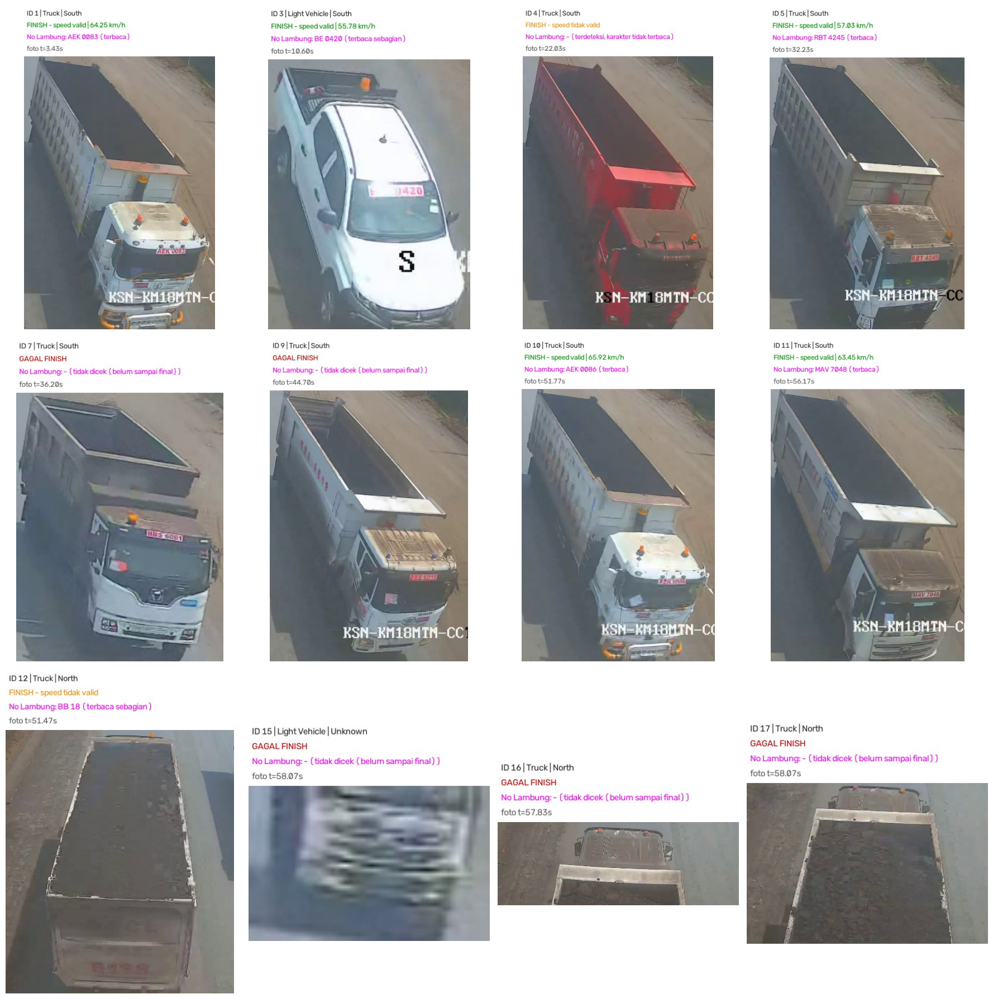

In [ ]:
import pandas as pd, json, cv2, math, matplotlib.pyplot as plt
tr = pd.read_csv(OUTPUT_DIR / 'tracks_report.csv', dtype=str, keep_default_na=False)
s = json.loads((OUTPUT_DIR / 'run_summary.json').read_text())
print('Jenis kendaraan  :', s['vehicle_types'])
print('Status kendaraan :', s['tracks_by_status'])
print('Nomor lambung    :', s['lambung_by_status'])
utama = tr[tr.frames_in_main != '0']
pd.set_option('display.max_colwidth', 120)
display(utama[['track_id', 'vehicle_type', 'first_seen_s', 'status_kendaraan', 'speed_kmh', 'is_overspeed',
               'lambung_status', 'lambung_text', 'keterangan']])

cards = sorted((OUTPUT_DIR / 'tracks').glob('track_*.jpg'))
cols = 4
rows = math.ceil(len(cards) / cols)
plt.figure(figsize=(18, 6 * rows))
for i, p in enumerate(cards):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
    plt.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
import pandas as pd, json
df = pd.read_csv(OUTPUT_DIR / 'events.csv', dtype=str, keep_default_na=False)
print('Jumlah event:', len(df), '| track_id unik:', df.track_id.nunique(), '| nomor lambung terbaca:', (df.plate_text != '').sum())
display(df)
print(json.dumps(json.loads((OUTPUT_DIR / 'run_summary.json').read_text()), indent=2))

Jumlah event: 7 | track_id unik: 7 | nomor lambung terbaca: 6


,event_id,source_video,track_id,event_timestamp_s,event_frame_index,travel_direction,vehicle_confidence,speed_start_timestamp_s,speed_end_timestamp_s,elapsed_seconds,...,speed_status,speed_limit_kmh,is_overspeed,plate_detected,plate_confidence,plate_bbox_xyxy,plate_timestamp_s,plate_text,measurement_valid,notes
0,km18_sample-00001,km18_sample.mp4,1,3.200000,96,South,0.9651,0.400000,3.033333,2.633333,...,valid,60,true,true,0.8393,"[1409,732,1569,787]",3.366667,AEK 0083,true,vehicle_type=Truck;ocr_reads=7/10
1,km18_sample-00002,km18_sample.mp4,3,10.033333,301,South,0.9531,6.800000,9.833333,3.033333,...,valid,60,false,true,0.8811,"[1401,945,1483,962]",10.666667,BE 0420,true,vehicle_type=Light Vehicle;ocr_reads=3/4
2,km18_sample-00003,km18_sample.mp4,4,21.800000,654,South,0.9488,18.966667,,,...,not_crossed_finish,60,,true,0.2101,"[1675,955,1781,999]",22.766667,,false,vehicle_type=Truck;ocr_reads=0/1
3,km18_sample-00004,km18_sample.mp4,5,31.966667,959,South,0.9563,28.800000,31.766667,2.966667,...,valid,60,false,true,0.7840,"[1543,795,1618,821]",32.166667,RBT 4245,true,vehicle_type=Truck;ocr_reads=11/15
4,km18_sample-00005,km18_sample.mp4,10,51.533333,1546,South,0.9562,48.800000,51.366667,2.566667,...,valid,60,true,true,0.8320,"[1471,686,1550,718]",51.600000,AEK 0086,true,vehicle_type=Truck;ocr_reads=10/14
5,km18_sample-00006,km18_sample.mp4,12,51.766667,1553,North,0.9617,,51.866667,,...,not_crossed_start,60,,true,0.8406,"[810,410,904,450]",52.333333,BB 18,false,vehicle_type=Truck;ocr_reads=5/24
6,km18_sample-00007,km18_sample.mp4,11,55.866667,1676,South,0.9567,53.066667,55.733333,2.666667,...,valid,60,true,true,0.5806,"[1436,670,1507,696]",55.933333,MAV 7048,true,vehicle_type=Truck;ocr_reads=5/6


{
  "video_name": "km18_sample.mp4",
  "fps": 30.0,
  "video_resolution": [
    1920,
    1080
  ],
  "total_frames_reported": 1743,
  "total_frames_read": 1743,
  "total_detections": 2127,
  "detections_without_track_id": 0,
  "unique_tracks": 12,
  "csv_events": 7,
  "speed_valid": 5,
  "overspeed": 3,
  "plate_detected": 7,
  "lambung_text_read": 6,
  "tracks_lost_before_final": 5,
  "vehicle_types": {
    "Truck": 10,
    "Light Vehicle": 2
  },
  "tracks_by_status": {
    "FINISH - speed valid": 5,
    "FINISH - speed tidak valid": 2,
    "GAGAL FINISH": 5
  },
  "lambung_by_status": {
    "terbaca": 4,
    "terbaca sebagian": 2,
    "terdeteksi, karakter tidak terbaca": 1
  },
  "speed_status_counts": {
    "valid": 5,
    "not_crossed_finish": 1,
    "not_crossed_start": 1
  },
  "processing_seconds": 167.45,
  "config": {
    "config_file": "_track_km18_01_V2.conf",
    "resolution_area": [
      1920,
      1080
    ],
    "distance_area_speed": 47.0,
    "speed_limit": 60.0,


In [ ]:

v = df[df.measurement_valid == 'true'].copy()
if len(v):
    v['cek'] = (v.distance_meter.astype(float) / v.elapsed_seconds.astype(float) * 3.6).round(2)
    v['ok'] = (v.cek - v.speed_kmh.astype(float)).abs() < 0.011
    display(v[['track_id', 'speed_start_timestamp_s', 'speed_end_timestamp_s', 'elapsed_seconds', 'speed_kmh', 'cek', 'ok', 'is_overspeed']])
print(df.speed_status.value_counts())

,track_id,speed_start_timestamp_s,speed_end_timestamp_s,elapsed_seconds,speed_kmh,cek,ok,is_overspeed
0,1,0.400000,3.033333,2.633333,64.25,64.25,True,true
1,3,6.800000,9.833333,3.033333,55.78,55.78,True,false
3,5,28.800000,31.766667,2.966667,57.03,57.03,True,false
4,10,48.800000,51.366667,2.566667,65.92,65.92,True,true
6,11,53.066667,55.733333,2.666667,63.45,63.45,True,true


speed_status
valid                 5
not_crossed_finish    1
not_crossed_start     1
Name: count, dtype: int64


In [ ]:
from IPython.display import HTML
from base64 import b64encode
vp = OUTPUT_DIR / 'annotated.mp4'
if vp.exists() and vp.stat().st_size < 40e6:
    display(HTML(f'<video width=900 controls src="data:video/mp4;base64,{b64encode(vp.read_bytes()).decode()}"></video>'))
else:
    print('Video:', vp, f'({vp.stat().st_size/1e6:.1f} MB)' if vp.exists() else '(tidak ada)')

In [ ]:
!mkdir -p "{DRIVE_DIR}/outputs" && cp -r "{OUTPUT_DIR}" "{DRIVE_DIR}/outputs/" && ls -la "{DRIVE_DIR}/outputs/{OUTPUT_DIR.name}"

total 10454
drwx------ 2 root root     4096 Oct 28 06:32 .
drwx------ 3 root root     4096 Oct 28 04:30 ..
-rw------- 1 root root 10691081 Oct 28 06:32 annotated.mp4
-rw------- 1 root root     1625 Oct 28 06:32 events.csv
-rw------- 1 root root     2372 Oct 28 06:32 run_summary.json


In [ ]:
# ===== EXPORT & DOWNLOAD SELURUH OUTPUT (1 folder -> 1 zip) =====
import shutil
from datetime import datetime
from pathlib import Path

RUN_DIR = Path(OUTPUT_DIR)                                   # mis. /content/outputs/run_01
assert RUN_DIR.exists() and any(RUN_DIR.iterdir()), f'Folder output kosong / belum ada: {RUN_DIR} -> jalankan Sel B dulu'

STAMP  = datetime.now().strftime('%Y%m%d_%H%M')
NAMA   = f'hauling_km18_output_{STAMP}'
EXPORT = RUN_DIR.parent / NAMA

# 1) salin SELURUH isi folder output ke satu folder export
if EXPORT.exists():
    shutil.rmtree(EXPORT)
shutil.copytree(RUN_DIR, EXPORT)

# 2) ringkasan isi
files_all = sorted(p for p in EXPORT.rglob('*') if p.is_file())
print(f'Folder export : {EXPORT}')
for p in files_all:
    if p.parent == EXPORT:
        print(f'  - {p.name:22s} {p.stat().st_size/1e6:8.2f} MB')
cards = list((EXPORT / 'tracks').glob('*.jpg')) if (EXPORT / 'tracks').exists() else []
print(f'  - tracks/                {len(cards)} foto per ID kendaraan')
print(f'Total {len(files_all)} file, {sum(p.stat().st_size for p in files_all)/1e6:.1f} MB')

# 3) zip jadi satu file
zip_path = Path(shutil.make_archive(str(EXPORT), 'zip', root_dir=EXPORT.parent, base_dir=EXPORT.name))
print(f'\nZIP           : {zip_path} ({zip_path.stat().st_size/1e6:.1f} MB)')

# 4) simpan cadangan ke Google Drive
try:
    drive_out = Path(DRIVE_DIR) / 'outputs' / 'exports'
    drive_out.mkdir(parents=True, exist_ok=True)
    shutil.copy2(zip_path, drive_out / zip_path.name)
    print(f'Tersimpan di  : {drive_out / zip_path.name}')
except Exception as e:
    print('Gagal menyalin ke Drive:', e)

# 5) download ke laptop
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception as e:
    print('Download otomatis gagal (ambil dari Drive / panel Files):', e)

Folder export : /content/outputs/hauling_km18_output_20261029_0932
  - annotated.mp4             10.48 MB
  - events.csv                 0.00 MB
  - run_summary.json           0.00 MB
  - tracks_report.csv          0.00 MB
  - tracks/                12 foto per ID kendaraan
Total 16 file, 10.9 MB

ZIP           : /content/outputs/hauling_km18_output_20261029_0932.zip (10.9 MB)
Tersimpan di  : /content/drive/MyDrive/Hauling Ruby/outputs/exports/hauling_km18_output_20261029_0932.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>